# Overview

Alphalens is designed to aid in the analysis of "alpha factors," data transformations that are used to predict future price movements of financial instruments. Alpha factors take the form of a single value for each asset on each day. The dimension of these values is not necessarily important. We evaluate an alpha factor by considering daily factor values relative to one another. 

It is important to note the difference between an alpha factor and a trading algorithm. A trading algorithm uses an alpha factor, or combination of alpha factors to generate trades.  Trading algorithms cover execution and risk constraints: the business of turning predictions into profits. Alpha factors, on the other hand, are focused soley on making predictions. This difference in scope lends itself to a difference in the methodologies used to evaluate alpha factors and trading algorithms. 

Alphalens does not contain analyses of things like transaction costs, capacity, or portfolio construction. Those interested in more implementation specific analyses are encouaged to check out [pyfolio](https://github.com/stefan-jansen/pyfolio-reloaded), a library specifically geared towards the evaluation of trading algorithms.

## Imports & Settings

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import alphalens
import seaborn as sns

In [3]:
%matplotlib inline
sns.set_style('white')

## Load & Transform Data

In [4]:
ticker_sector = {
    "ACN": 0, "ATVI": 0, "ADBE": 0, "AMD": 0, "AKAM": 0, "ADS": 0, "GOOGL": 0, "GOOG": 0,
    "APH": 0, "ADI": 0, "ANSS": 0, "AAPL": 0, "AMAT": 0, "ADSK": 0, "ADP": 0, "AVGO": 0,
    "AMG": 1, "AFL": 1, "ALL": 1, "AXP": 1, "AIG": 1, "AMP": 1, "AON": 1, "AJG": 1, "AIZ": 1, "BAC": 1,
    "BK": 1, "BBT": 1, "BRK.B": 1, "BLK": 1, "HRB": 1, "BHF": 1, "COF": 1, "CBOE": 1, "SCHW": 1, "CB": 1,
    "ABT": 2, "ABBV": 2, "AET": 2, "A": 2, "ALXN": 2, "ALGN": 2, "AGN": 2, "ABC": 2, "AMGN": 2, "ANTM": 2,
    "BCR": 2, "BAX": 2, "BDX": 2, "BIIB": 2, "BSX": 2, "BMY": 2, "CAH": 2, "CELG": 2, "CNC": 2, "CERN": 2,
    "MMM": 3, "AYI": 3, "ALK": 3, "ALLE": 3, "AAL": 3, "AME": 3, "AOS": 3, "ARNC": 3, "BA": 3, "CHRW": 3,
    "CAT": 3, "CTAS": 3, "CSX": 3, "CMI": 3, "DE": 3, "DAL": 3, "DOV": 3, "ETN": 3, "EMR": 3, "EFX": 3,
    "AES": 4, "LNT": 4, "AEE": 4, "AEP": 4, "AWK": 4, "CNP": 4, "CMS": 4, "ED": 4, "D": 4, "DTE": 4,
    "DUK": 4, "EIX": 4, "ETR": 4, "ES": 4, "EXC": 4, "FE": 4, "NEE": 4, "NI": 4, "NRG": 4, "PCG": 4,
    "ARE": 5, "AMT": 5, "AIV": 5, "AVB": 5, "BXP": 5, "CBG": 5, "CCI": 5, "DLR": 5, "DRE": 5,
    "EQIX": 5, "EQR": 5, "ESS": 5, "EXR": 5, "FRT": 5, "GGP": 5, "HCP": 5, "HST": 5, "IRM": 5, "KIM": 5,
    "APD": 6, "ALB": 6, "AVY": 6, "BLL": 6, "CF": 6, "DWDP": 6, "EMN": 6, "ECL": 6, "FMC": 6, "FCX": 6,
    "IP": 6, "IFF": 6, "LYB": 6, "MLM": 6, "MON": 6, "MOS": 6, "NEM": 6, "NUE": 6, "PKG": 6, "PPG": 6,
    "T": 7, "CTL": 7, "VZ": 7,
    "MO": 8, "ADM": 8, "BF.B": 8, "CPB": 8, "CHD": 8, "CLX": 8, "KO": 8, "CL": 8, "CAG": 8,
    "STZ": 8, "COST": 8, "COTY": 8, "CVS": 8, "DPS": 8, "EL": 8, "GIS": 8, "HSY": 8, "HRL": 8,
    "AAP": 9, "AMZN": 9, "APTV": 9, "AZO": 9, "BBY": 9, "BWA": 9, "KMX": 9, "CCL": 9,
    "APC": 10, "ANDV": 10, "APA": 10, "BHGE": 10, "COG": 10, "CHK": 10, "CVX": 10, "XEC": 10, "CXO": 10,
    "COP": 10, "DVN": 10, "EOG": 10, "EQT": 10, "XOM": 10, "HAL": 10, "HP": 10, "HES": 10, "KMI": 10
}

See [yfinance](https://github.com/ranaroussi/yfinance) for details.

In [5]:
import pandas as pd
import yfinance as yf

# Use yfinance directly instead of pandas-datareader
tickers = list(ticker_sector.keys())
df = yf.download(tickers, start='2015-01-01', end='2017-01-01')

# Ensure datetime and UTC formatting
df.index = pd.to_datetime(df.index, utc=True)

$ANTM: possibly delisted; no timezone found
[***                    7%                       ]  12 of 182 completed$APC: possibly delisted; no price data found  (1d 2015-01-01 -> 2017-01-01) (Yahoo error = "Data doesn't exist for startDate = 1420088400, endDate = 1483246800")
[*******               14%                       ]  25 of 182 completed$BHF: possibly delisted; no price data found  (1d 2015-01-01 -> 2017-01-01) (Yahoo error = "Data doesn't exist for startDate = 1420088400, endDate = 1483246800")
[********              17%                       ]  31 of 182 completed$AET: possibly delisted; no price data found  (1d 2015-01-01 -> 2017-01-01) (Yahoo error = "No data found, symbol may be delisted")
[*********             18%                       ]  32 of 182 completed$ANDV: possibly delisted; no price data found  (1d 2015-01-01 -> 2017-01-01) (Yahoo error = "No data found, symbol may be delisted")
[**********            20%                       ]  36 of 182 completed$DWDP: possi

In [6]:
df = df.stack()
df.index.names = ['date', 'asset']
df.info()

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 74088 entries, (Timestamp('2015-01-02 00:00:00+0000', tz='UTC'), 'A') to (Timestamp('2016-12-30 00:00:00+0000', tz='UTC'), 'XOM')
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  0 non-null      float64
 1   Close      74088 non-null  float64
 2   High       74088 non-null  float64
 3   Low        74088 non-null  float64
 4   Open       74088 non-null  float64
 5   Volume     74088 non-null  float64
dtypes: float64(6)
memory usage: 3.7+ MB


## Compute Factor

For demonstration purposes we will create a predictive factor. To cheat we will look at future prices (5 days into the future) to make sure we'll rank stocks that will perform well high, and vice versa.

In [7]:
lookahead_bias_days = 5

predictive_factor = df.loc[:, 'Open'].unstack('asset')
predictive_factor = predictive_factor.pct_change(lookahead_bias_days)
# introduce look-ahead bias and make the factor predictive
predictive_factor = predictive_factor.shift(-lookahead_bias_days)

predictive_factor = predictive_factor.stack()

In [8]:
predictive_factor.head()

date                       asset
2015-01-02 00:00:00+00:00  A       -0.004371
                           AAL     -0.011238
                           AAP     -0.005595
                           AAPL     0.011491
                           ABBV     0.019101
dtype: float64

## Get pricing info

The pricing data passed to alphalens should contain the entry price for the assets so it must reflect the next available price after a factor value was observed at a given timestamp. Those prices must not be used in the calculation of the factor values for that time. Always double check to ensure you are not introducing lookahead bias to your study.

The pricing data must also contain the exit price for the assets, for period 1 the price at the next timestamp will be used, for period 2 the price after 2 timestats will be used and so on.

There are no restrinctions/assumptions on the time frequencies a factor should be computed at and neither on the specific time a factor should be traded (trading at the open vs trading at the close vs intraday trading), it is only required that factor and price DataFrames are properly aligned given the rules above.

In our example, before the trading starts every day, we observe yesterday factor values. The price we pass to alphalens is the next available price after that factor observation: the daily open price that will be used as assets entry price. Also, we are not adding additional prices so the assets exit price will be the following days open prices (how many days depends on 'periods' argument). The retuns computed by Alphalens will therefore based on  assets open prices.

In [9]:
pricing = df.loc[:, 'Open'].iloc[1:].unstack('asset')
pricing.head()

asset,AAL,AAP,AAPL,ABBV,ABT,ACN,ADBE,ADI,ADM,ADP,...,NUE,PCG,PKG,PPG,SCHW,STZ,T,VZ,XOM,A
date,,,,,,,,,,,,,,,,,,,,,
2015-01-02 00:00:00+00:00,51.430489,138.554591,24.627197,40.838411,36.032902,73.433121,72.699997,44.072140,37.030298,63.886637,...,37.561284,47.862216,55.612517,93.336626,26.352333,82.295843,11.034959,24.936390,56.423156,NaN
2015-01-05 00:00:00+00:00,51.515765,136.246084,23.941821,40.875851,35.674575,72.098292,72.209999,43.850518,36.498243,64.094497,...,37.011927,48.282840,54.948535,91.685149,25.971040,81.633557,11.126947,24.978839,56.331412,36.626441
2015-01-06 00:00:00+00:00,51.421014,134.859257,23.554911,40.950739,35.825870,71.656062,71.949997,43.320192,35.795950,64.132999,...,36.012422,48.622931,54.786048,90.736243,25.312451,85.682554,11.094093,24.824982,55.193785,36.163167
2015-01-07 00:00:00+00:00,50.577733,135.763719,23.700833,40.295467,35.618827,71.377640,70.769997,42.338700,35.256797,63.301495,...,35.806429,48.551329,54.510557,90.037701,24.662518,84.718492,11.239839,25.188450,55.444563,35.899736
2015-01-08 00:00:00+00:00,50.672493,140.716689,24.149645,42.535845,35.985117,72.884465,71.400002,43.051070,34.965965,64.641155,...,35.936128,48.998812,54.856699,91.354048,25.295113,90.821342,11.126029,24.920037,55.811536,36.553776


Often, we'd want to know how our factor looks across various groupings (sectors, industires, countries, etc.), in this example let's use sectors. To generate sector level breakdowns, you'll need to pass alphalens a sector mapping for each traded name. 

This mapping can come in the form of a MultiIndexed Series (with the same date/symbol index as your factor value) if you want to provide a sector mapping for each symbol on each day. 

If you'd like to use constant sector mappings, you may pass symbol to sector mappings as a dict.

If your sector mappings come in the form of codes (as they do in this tutorial), you may also pass alphalens a dict of sector names to use in place of sector codes.

In [10]:
sector_names = {
    0: "information_technology",
    1: "financials",
    2: "health_care",
    3: "industrials",
    4: "utilities",
    5: "real_estate",
    6: "materials",
    7: "telecommunication_services",
    8: "consumer_staples",
    9: "consumer_discretionary",
    10: "energy"
}

## Format tearsheet input data

Alphalens contains a handy data formatting function to transform your factor and pricing data into the exact inputs expected by the tear sheet functions.

In [11]:
factor_data = alphalens.utils.get_clean_factor_and_forward_returns(predictive_factor,
                                                                   pricing,
                                                                   quantiles=5,
                                                                   bins=None,
                                                                   groupby=ticker_sector,
                                                                   groupby_labels=sector_names)

Dropped 1.0% entries from factor data: 1.0% in forward returns computation and 0.0% in binning phase (set max_loss=0 to see potentially suppressed Exceptions).
max_loss is 35.0%, not exceeded: OK!


The function inform the user how much data was dropped after formatting the input data. Factor data can be partially dropped due to being flawed itself (e.g. NaNs), not having provided enough price data to compute forward returns for all factor values, or because it is not possible to perform binning. It is possible to control the maximum allowed data loss using 'max_loss' argument.

In [12]:
factor_data.head()

1D        5D       10D    factor  \
date                      asset                                           
2015-01-02 00:00:00+00:00 AAL    0.001658 -0.011238 -0.090273 -0.011238   
                          AAP   -0.016661 -0.005595 -0.079888 -0.005595   
                          AAPL  -0.027830  0.011491 -0.039142  0.011491   
                          ABBV   0.000917  0.019101 -0.030829  0.019101   
                          ABT   -0.009944  0.011050 -0.026920  0.011050   

                                                  group  factor_quantile  
date                      asset                                           
2015-01-02 00:00:00+00:00 AAL               industrials                2  
                          AAP    consumer_discretionary                2  
                          AAPL   information_technology                4  
                          ABBV              health_care                4  
                          ABT               health_care                4

You'll notice that we've placed all of the information we need for our calculations into one dataframe. Variables are the columns, and observations are each row.

The integer columns represents the forward returns or the daily price change for the N days after a timestamp. The 1 day forward return for AAPL on 2014-12-2 is the percent change in the AAPL open price on 2014-12-2 and the AAPL open price on 2014-12-3. The 5 day forward return is the percent change from open 2014-12-2 to open 2014-12-9 (5 trading days) divided by 5.

# Returns Analysis

Returns analysis gives us a raw description of a factor's value that shows us the power of a factor in real currency values.

One of the most basic ways to look at a factor's predictive power is to look at the mean return of different factor quantile. 

## Performance Metrics & Plotting Functions

In [13]:
mean_return_by_q_daily, std_err = alphalens.performance.mean_return_by_quantile(
    factor_data, by_date=True)

In [14]:
mean_return_by_q_daily.head()

1D        5D       10D
factor_quantile date                                                   
1               2015-01-02 00:00:00+00:00 -0.007835 -0.039865 -0.056606
                2015-01-05 00:00:00+00:00 -0.013949 -0.042870 -0.051280
                2015-01-06 00:00:00+00:00 -0.009260 -0.037581 -0.036828
                2015-01-07 00:00:00+00:00 -0.006245 -0.040240 -0.040523
                2015-01-08 00:00:00+00:00 -0.007442 -0.047272 -0.046697

In [15]:
mean_return_by_q, std_err_by_q = alphalens.performance.mean_return_by_quantile(factor_data,
                                                                               by_date=False)

In [16]:
mean_return_by_q.head()

,1D,5D,10D
factor_quantile,,,
1,-0.008450,-0.040355,-0.040361
2,-0.002608,-0.013216,-0.013710
3,-0.000159,-0.000330,-0.000233
4,0.002726,0.012405,0.012472
5,0.008491,0.041461,0.041788


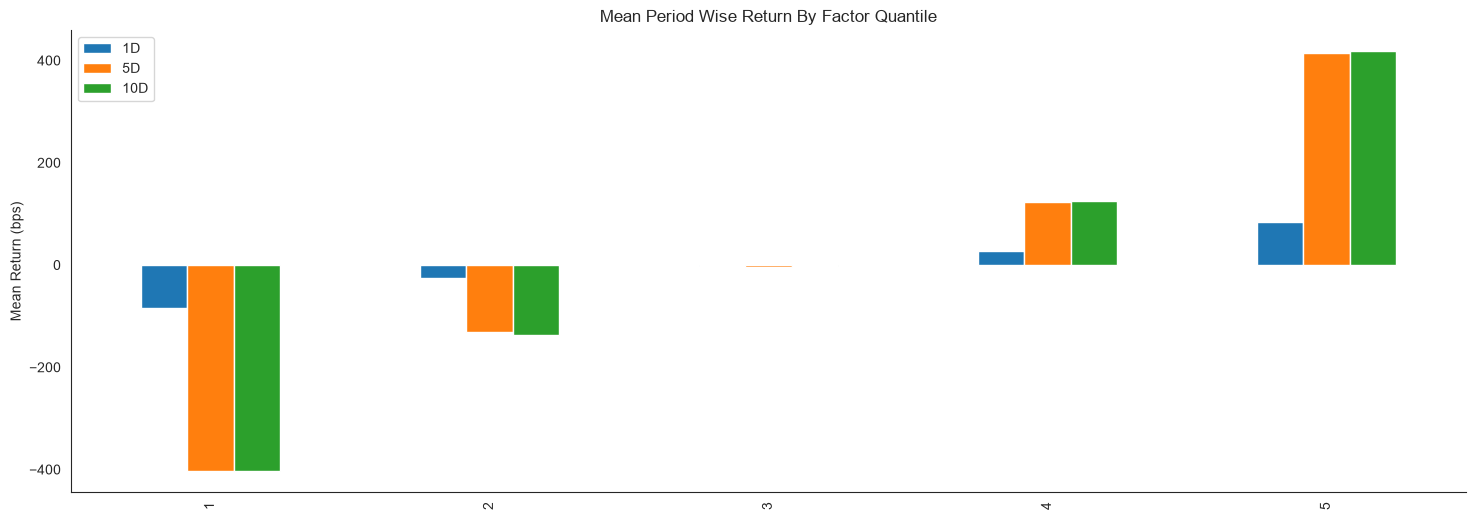

In [17]:
alphalens.plotting.plot_quantile_returns_bar(mean_return_by_q)
sns.despine()

By looking at the mean return by quantile we can get a real look at how well the factor differentiates forward returns across the signal values. Obviously we want securities with a better signal to exhibit higher returns. For a good factor we'd expect to see negative values in the lower quartiles and positive values in the upper quantiles.

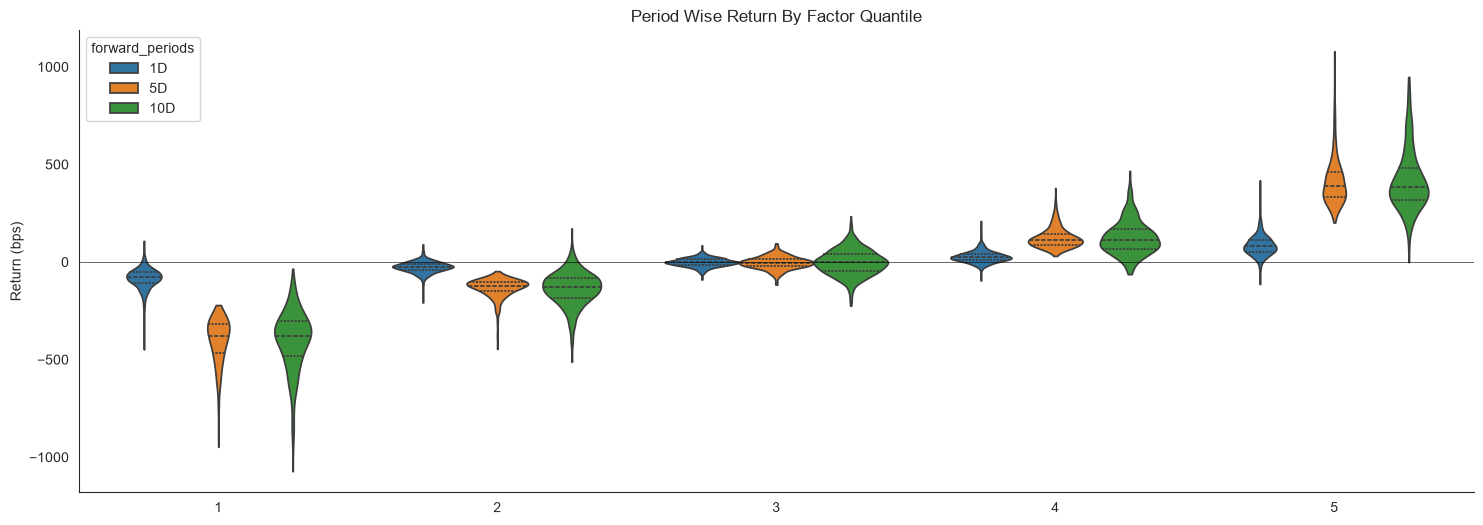

In [18]:
alphalens.plotting.plot_quantile_returns_violin(mean_return_by_q_daily)
sns.despine()

This violin plot is similar to the one before it but shows more information about the underlying data. It gives a better idea about the range of values, the median, and the inter-quartile range. What gives the plots their shape is the application of a probability density of the data at different values.

In [19]:
quant_return_spread, std_err_spread = alphalens.performance.compute_mean_returns_spread(mean_return_by_q_daily,
                                                                                        upper_quant=5,
                                                                                        lower_quant=1,
                                                                                        std_err=std_err)

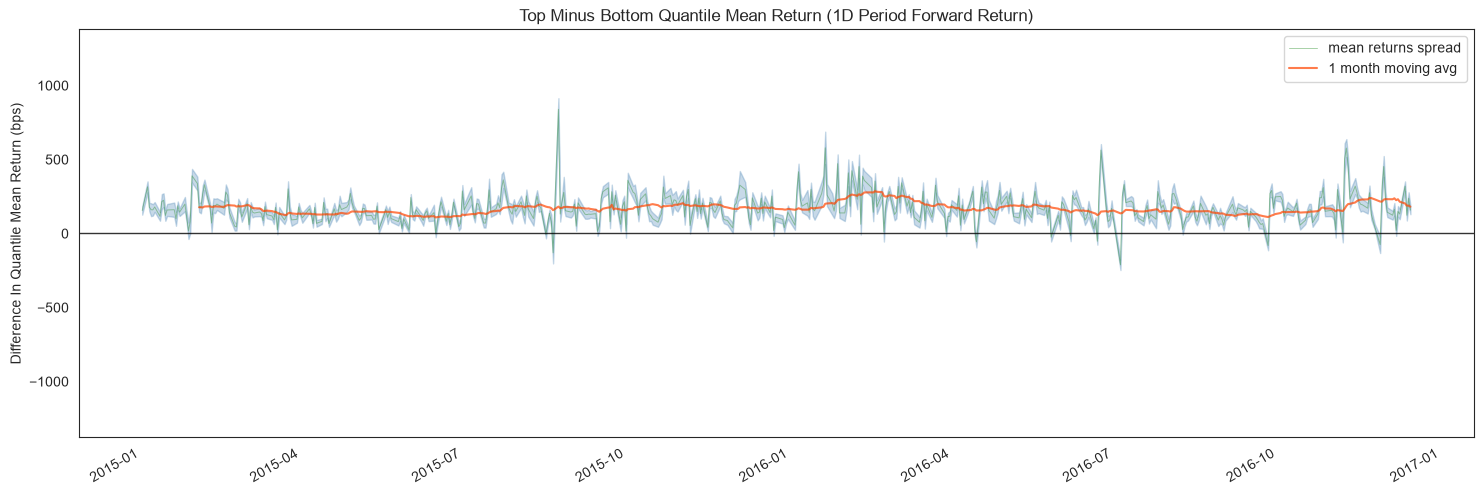

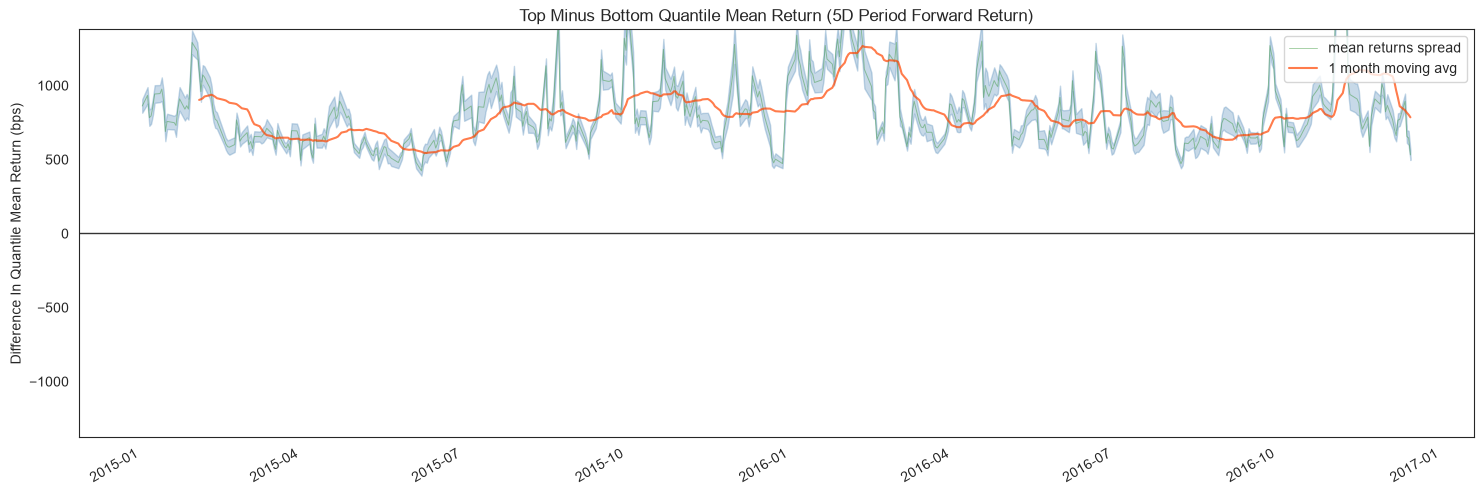

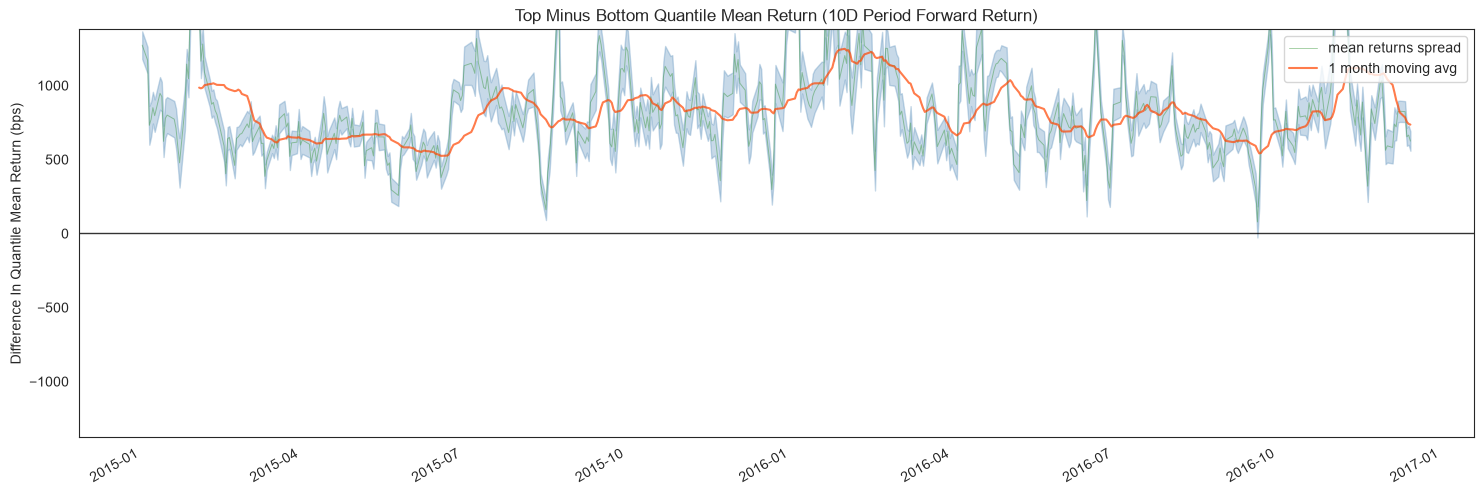

In [20]:
alphalens.plotting.plot_mean_quantile_returns_spread_time_series(
    quant_return_spread, std_err_spread);

This rolling forward returns spread graph allows us to look at the raw spread in basis points between the top and bottom quantiles over time. The green line is the returns spread while the orange line is a 1 month average to smooth the data and make it easier to visualize.

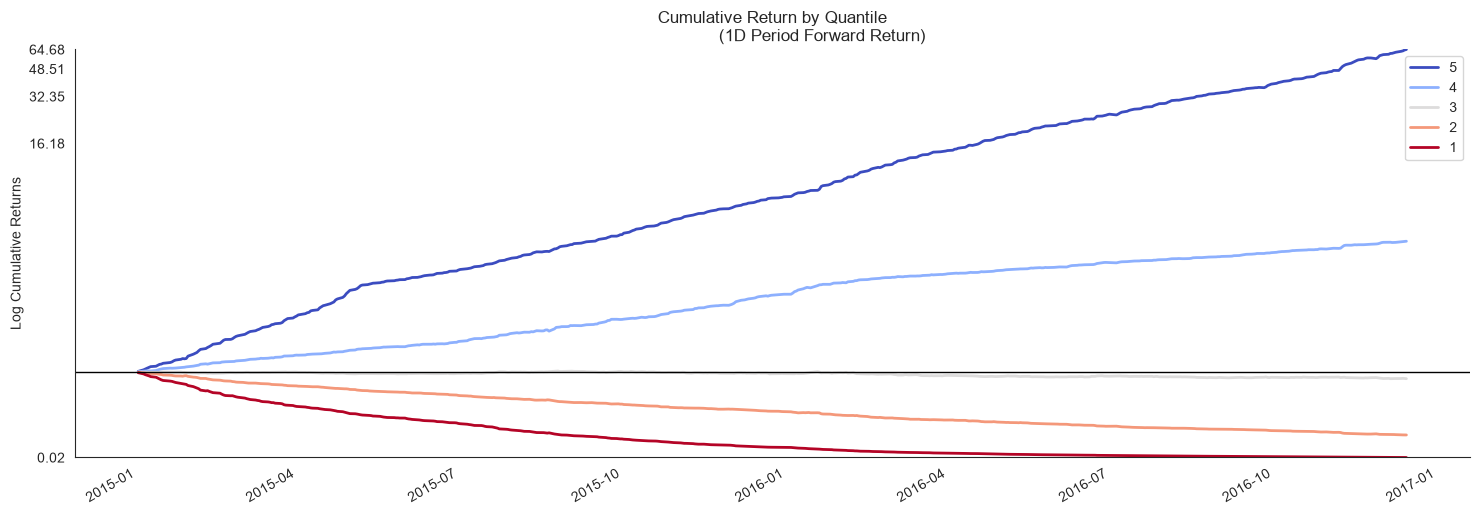

In [21]:
alphalens.plotting.plot_cumulative_returns_by_quantile(mean_return_by_q_daily['1D'], period='1D')
sns.despine();

By looking at the cumulative returns by factor quantile we can get an intuition for which quantiles are contributing the most to the factor and at what time. Ideally we would like to see a these curves originate at the same value on the left and spread out like a fan as they move to the right through time, with the higher quantiles on the top.

In [22]:
ls_factor_returns = alphalens.performance.factor_returns(factor_data)

In [23]:
ls_factor_returns.head()

,1D,5D,10D
date,,,
2015-01-02 00:00:00+00:00,0.007575,0.040552,0.059361
2015-01-05 00:00:00+00:00,0.014418,0.046100,0.053177
2015-01-06 00:00:00+00:00,0.008443,0.041304,0.039865
2015-01-07 00:00:00+00:00,0.007593,0.041080,0.038396
2015-01-08 00:00:00+00:00,0.006777,0.044313,0.042293


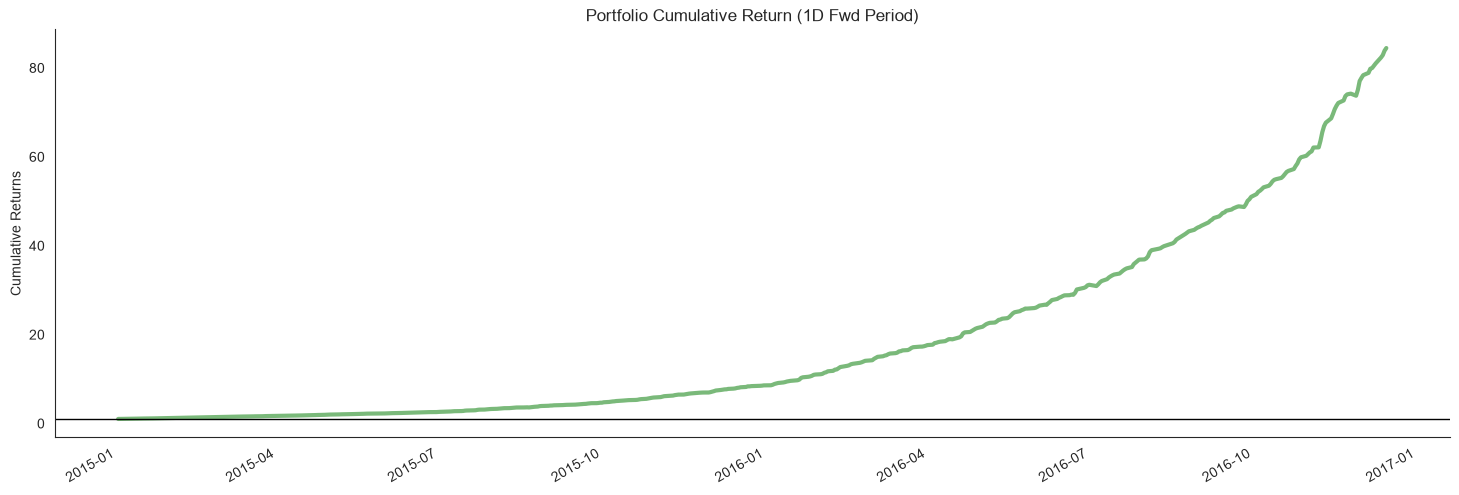

In [24]:
alphalens.plotting.plot_cumulative_returns(ls_factor_returns['1D'], 
                                           period='1D')
sns.despine();

While looking at quantiles is important we must also look at the factor returns as a whole. The cumulative factor long/short returns plot lets us view the combined effects overtime of our entire factor.

In [25]:
alpha_beta = alphalens.performance.factor_alpha_beta(factor_data)

In [26]:
alpha_beta

,1D,5D,10D
Ann. alpha,8.549735,7.894738,1.977245
beta,0.095216,0.075039,0.064734


A very important part of factor returns analysis is determing the alpha, and how significant it is. Here we surface the annualized alpha, and beta.

## Returns Tear Sheet

We can view all returns analysis calculations together.

Returns Analysis


,1D,5D,10D
Ann. alpha,8.550,7.895,1.977
beta,0.095,0.075,0.065
Mean Period Wise Return Top Quantile (bps),84.906,81.579,41.022
Mean Period Wise Return Bottom Quantile (bps),-84.503,-82.045,-41.113
Mean Period Wise Spread (bps),169.409,163.634,82.155


<Figure size 640x480 with 0 Axes>

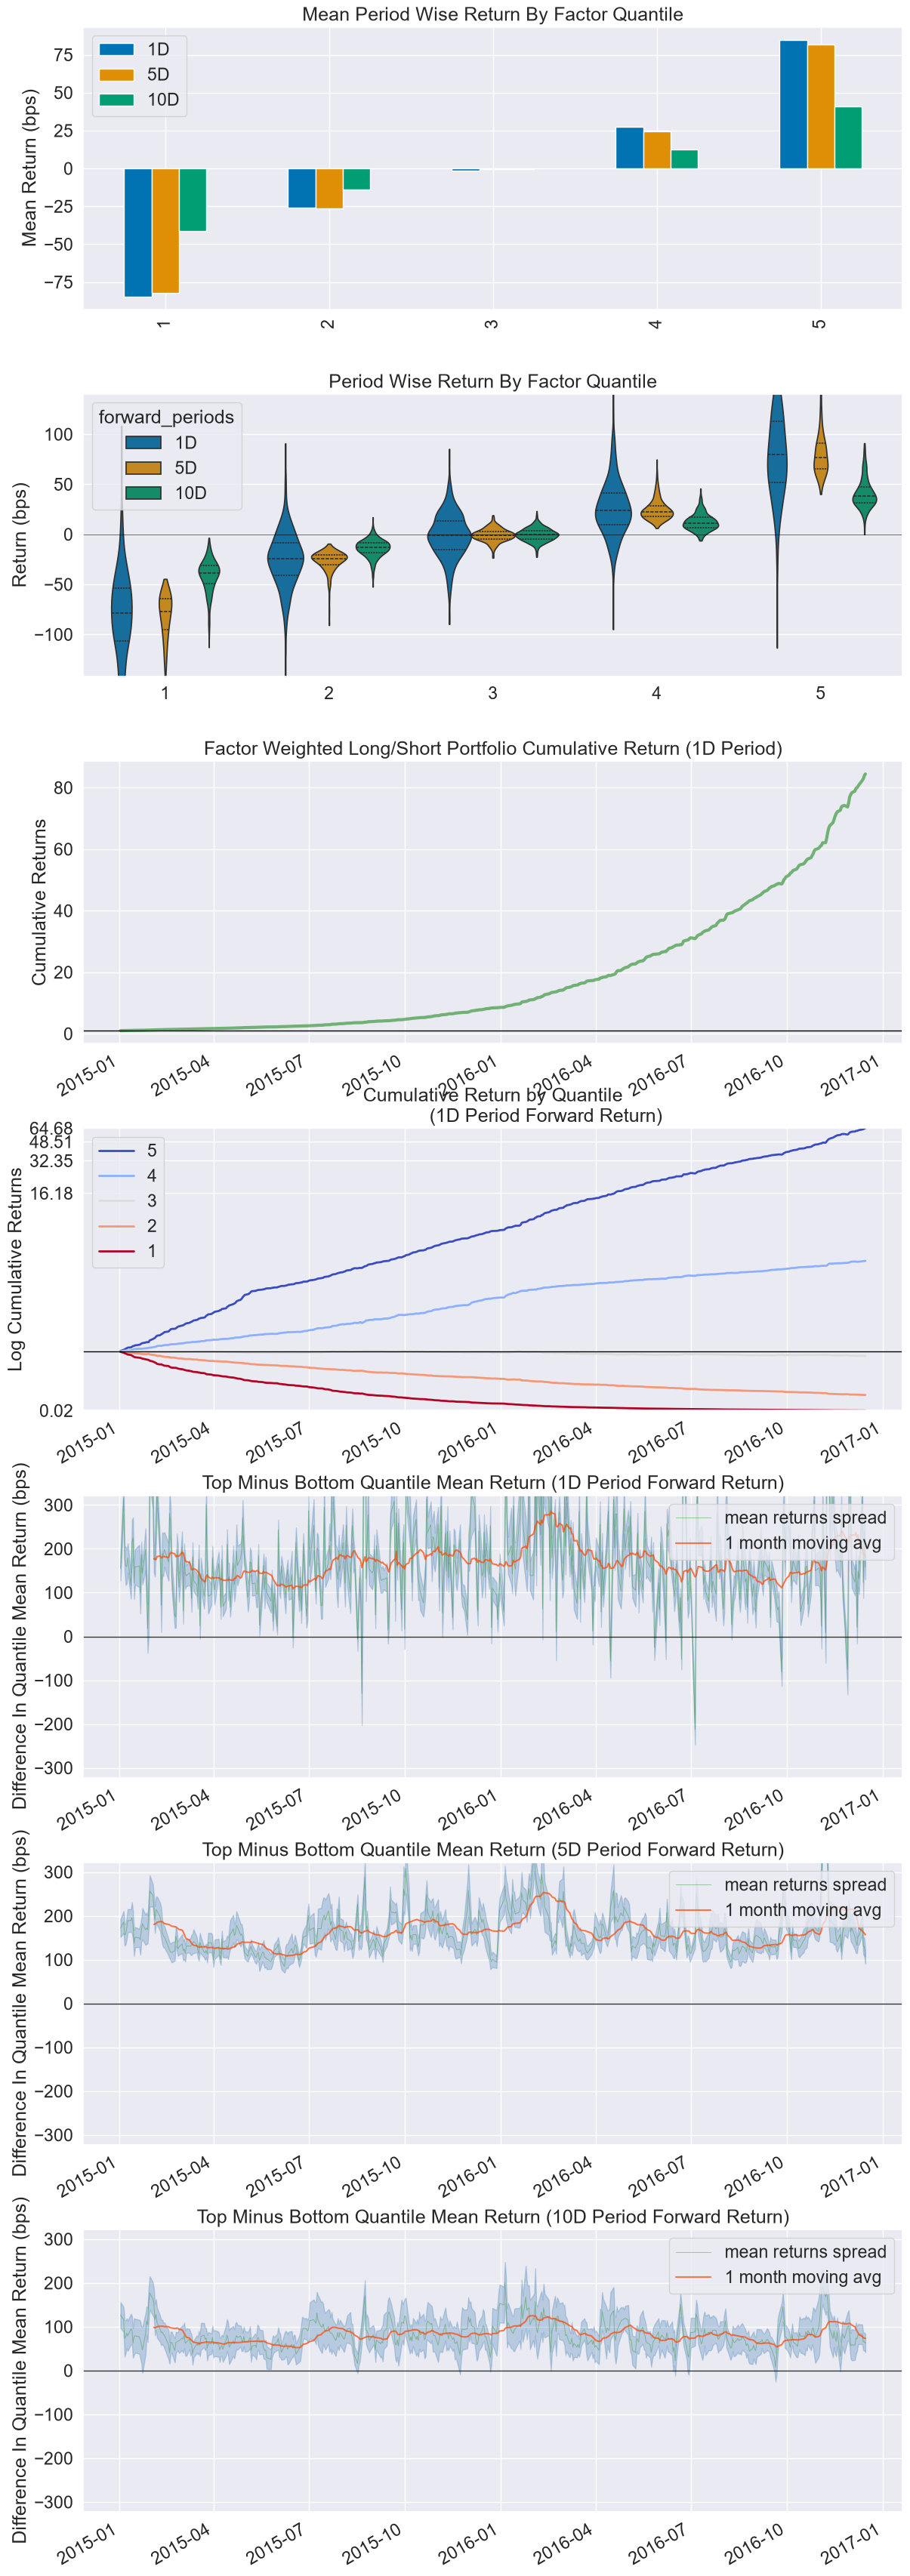

In [27]:
alphalens.tears.create_returns_tear_sheet(factor_data);

# Information Analysis

Information Analysis is a way for us to evaluate the predicitive value of a factor without the confounding effects of transaction costs. The main way we look at this is through the Information Coefficient (IC).

From Wikipedia...

>The information coefficient (IC) is a measure of the merit of a predicted value. In finance, the information coefficient is used as a performance metric for the predictive skill of a financial analyst. The information coefficient is similar to correlation in that it can be seen to measure the linear relationship between two random variables, e.g. predicted stock returns and the actualized returns. The information coefficient ranges from 0 to 1, with 0 denoting no linear relationship between predictions and actual values (poor forecasting skills) and 1 denoting a perfect linear relationship (good forecasting skills).

## Performance Metrics & Plotting Functions

In [28]:
ic = alphalens.performance.factor_information_coefficient(factor_data)

In [29]:
ic.head()

,1D,5D,10D
date,,,
2015-01-02 00:00:00+00:00,0.525667,1.0,0.849375
2015-01-05 00:00:00+00:00,0.730516,1.0,0.814581
2015-01-06 00:00:00+00:00,0.504163,1.0,0.644890
2015-01-07 00:00:00+00:00,0.447419,1.0,0.657761
2015-01-08 00:00:00+00:00,0.352179,1.0,0.733338


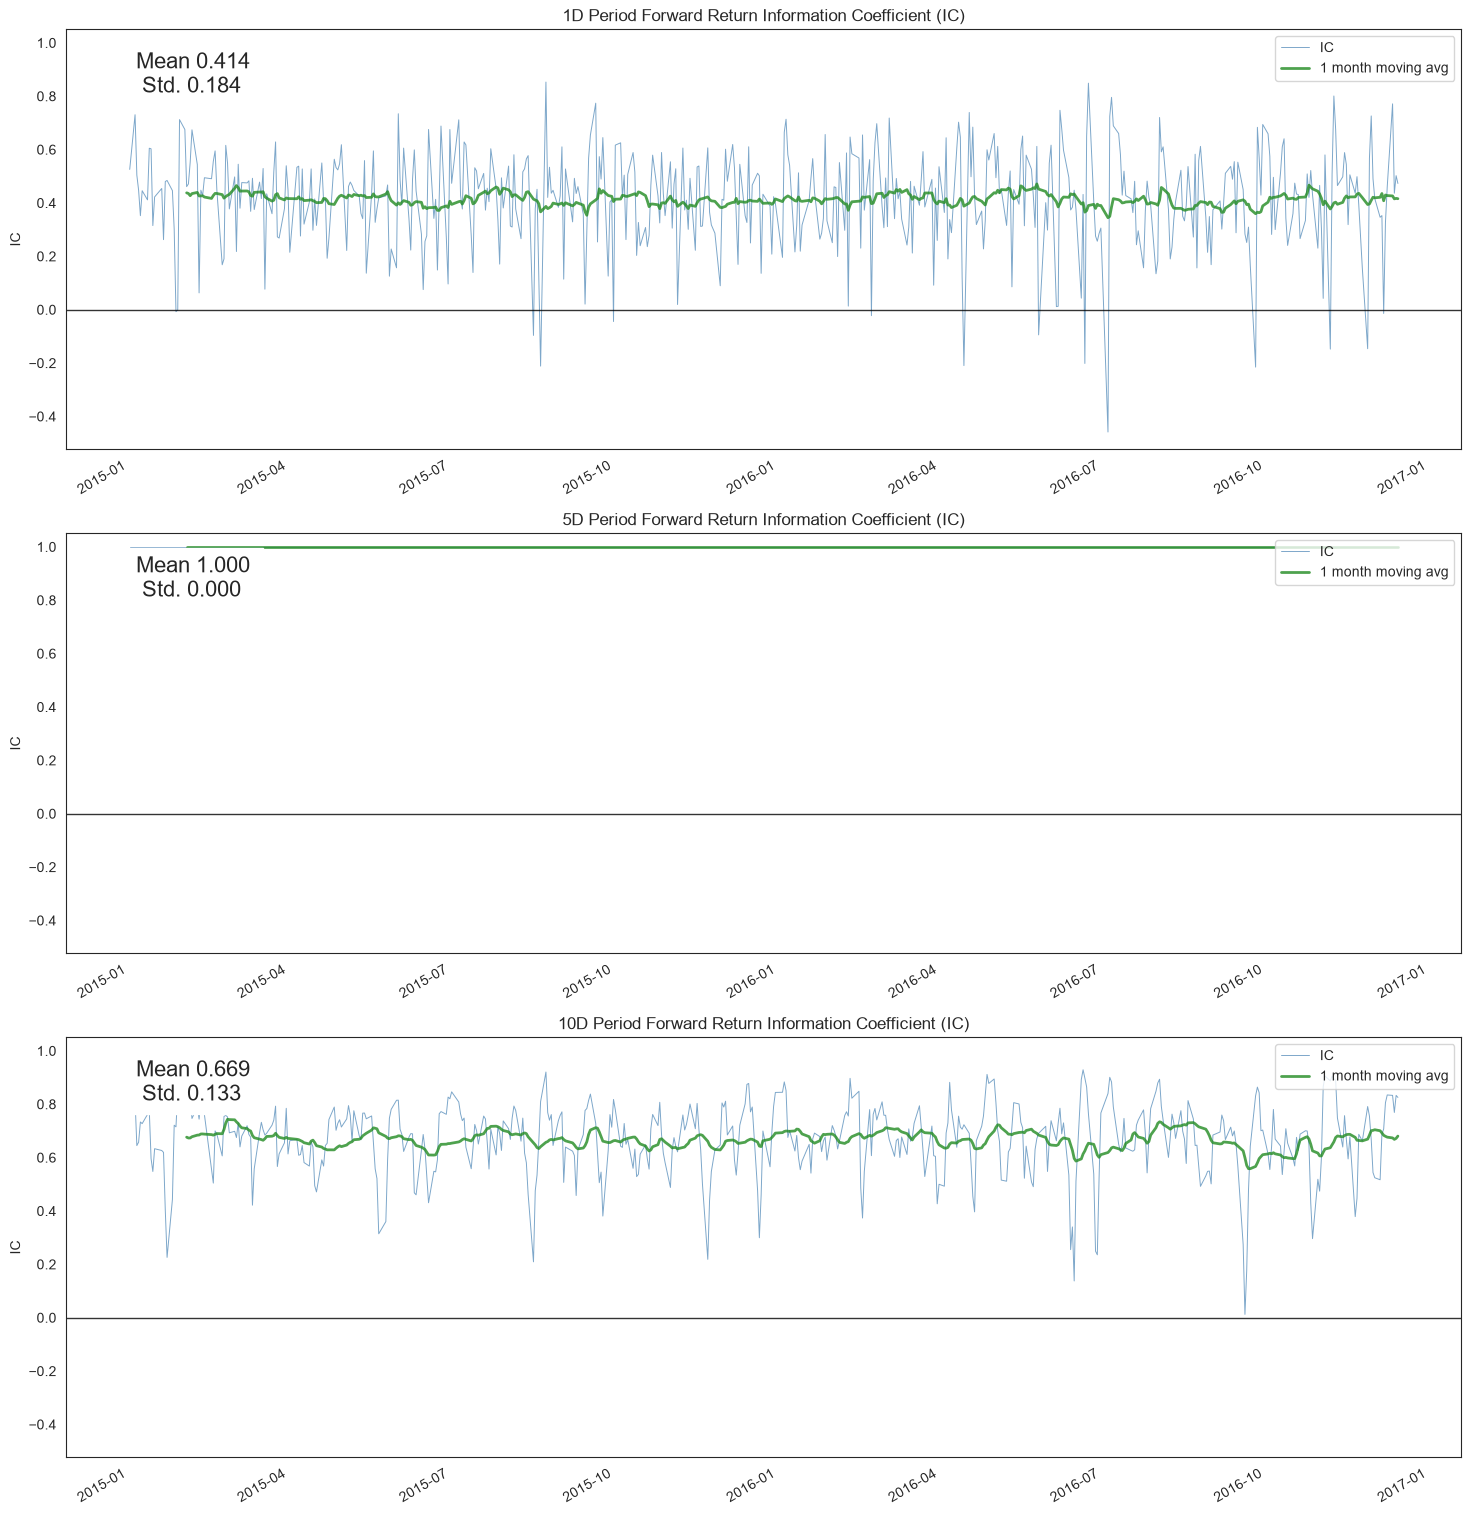

In [30]:
alphalens.plotting.plot_ic_ts(ic);

By looking at the IC each day we can understand how theoretically predicitive our factor is overtime. We like our mean IC to be high and the standard deviation, or volatility of it, to be low. We want to find consistently predictive factors.

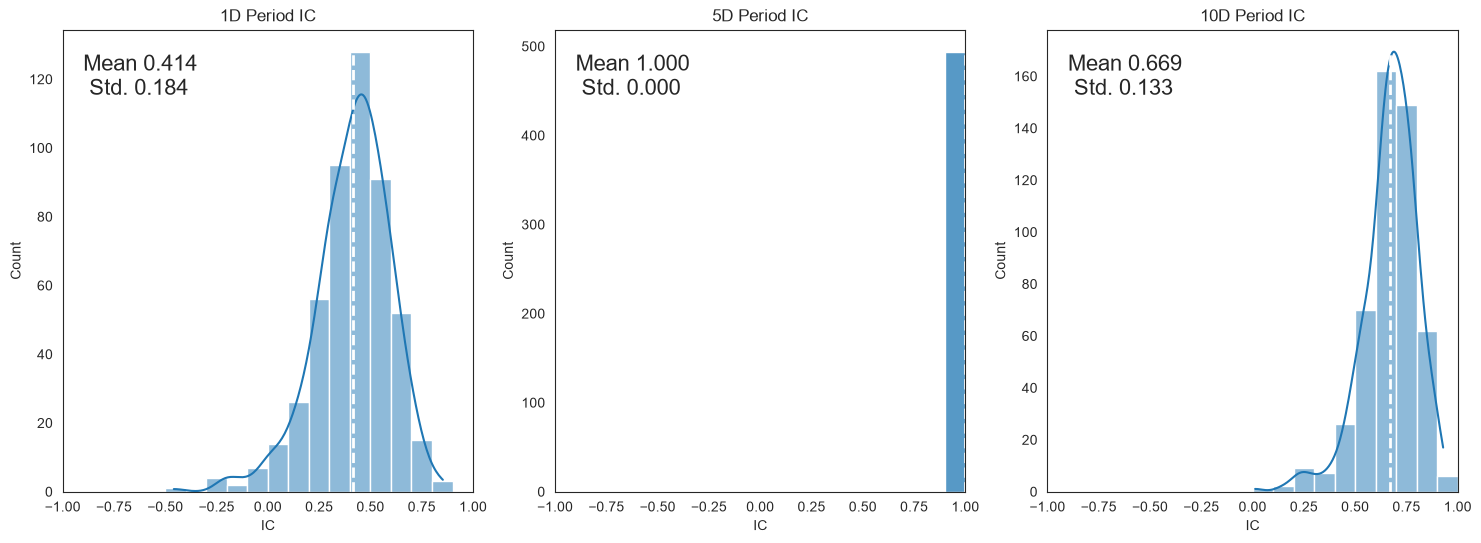

In [31]:
alphalens.plotting.plot_ic_hist(ic);

Looking at a histogram of the daily IC values can indicate how the factor behaves most of the time, where the likely IC values will fall, it also allows us to see if the factor has fat tails.

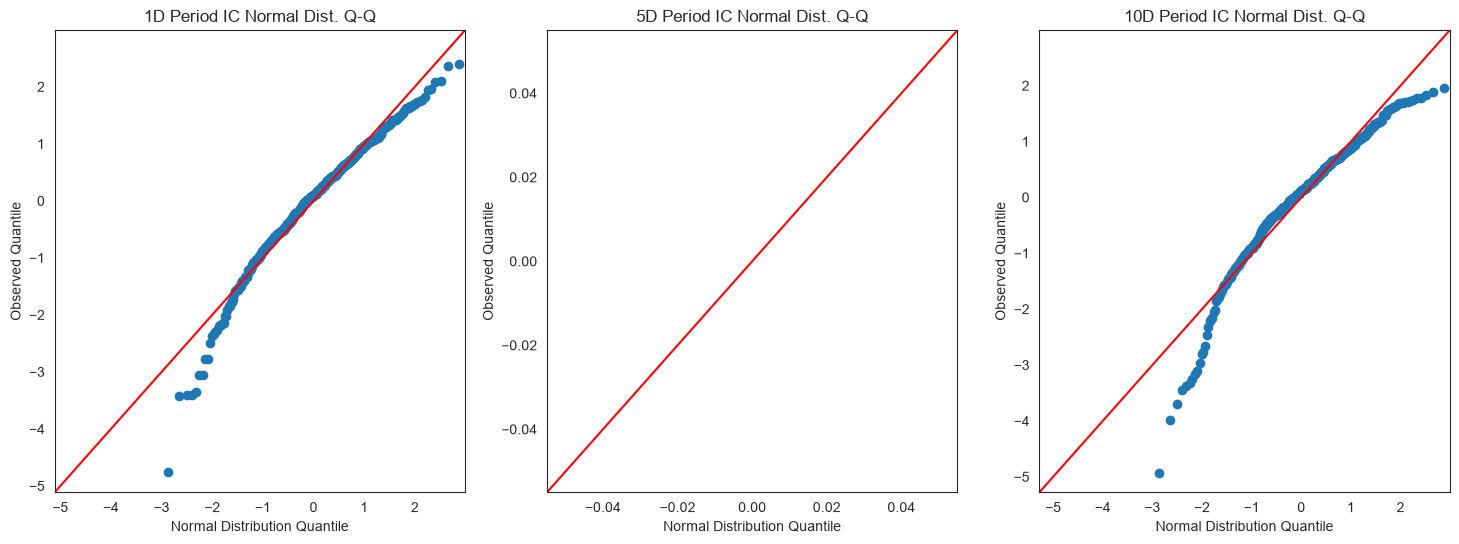

In [32]:
alphalens.plotting.plot_ic_qq(ic);

These Q-Q plots show the difference in shape between the distribution of IC values and a normal distribution. This is especially helpful in seeing how the most extreme values in the distribution affect the predicitive power.

In [33]:
mean_monthly_ic = alphalens.performance.mean_information_coefficient(factor_data, 
                                                                     by_time='M')

In [34]:
mean_monthly_ic.head()

,1D,5D,10D
date,,,
2015-01-31 00:00:00+00:00,0.424780,1.0,0.660193
2015-02-28 00:00:00+00:00,0.463163,1.0,0.731806
2015-03-31 00:00:00+00:00,0.418573,1.0,0.675599
2015-04-30 00:00:00+00:00,0.419764,1.0,0.637468
2015-05-31 00:00:00+00:00,0.395808,1.0,0.668178


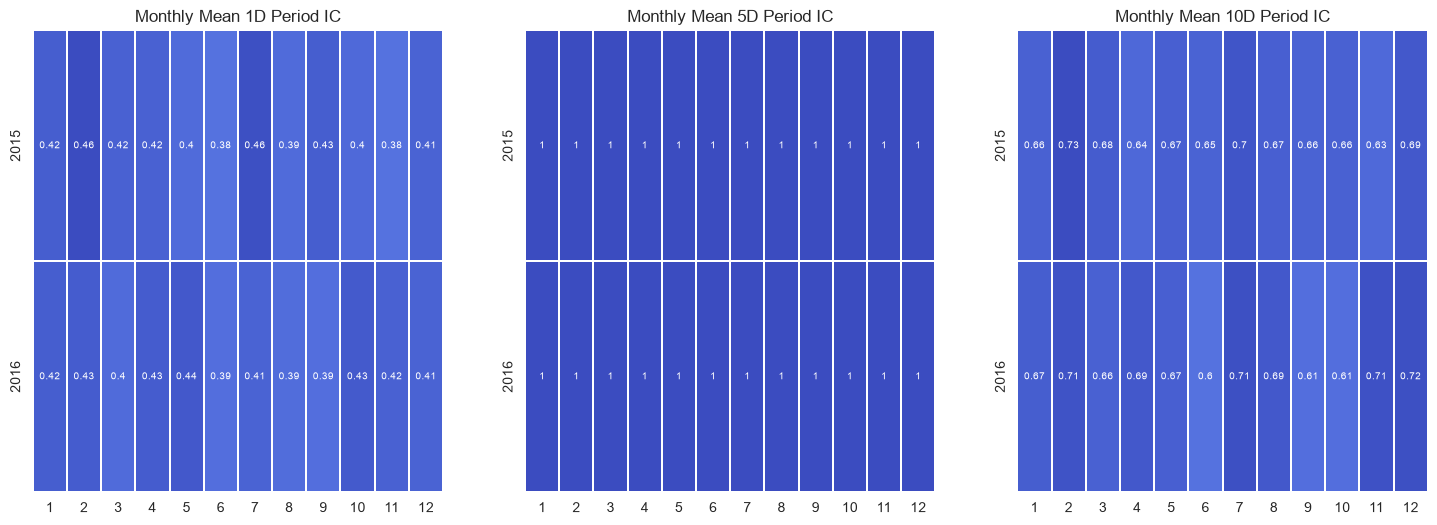

In [35]:
alphalens.plotting.plot_monthly_ic_heatmap(mean_monthly_ic);

By displaying the IC data in heatmap format we can get an idea about the consistency of the factor, and how it behaves during different market regimes/seasons.

## Information Tear Sheet

We can view all information analysis calculations together.

Information Analysis (spearman)


,1D,5D,10D
IC Mean (spearman),0.414,1.000000e+00,0.669
IC Std.,0.184,0.000000e+00,0.133
Risk-Adjusted IC (ICIR),2.254,inf,5.020
t-stat(IC),50.087,inf,111.585
p-value(IC),0.000,0.000000e+00,0.000
IC Skew,-0.801,NaN,-1.089
IC Kurtosis,1.554,NaN,2.401
lag1_autocorr,0.021,NaN,0.672
lb_pvalue,0.634,NaN,0.000
nw_tstat,49.611,1.416309e+16,86.452


Information Analysis (pearson)


,1D,5D,10D
IC Mean (pearson),0.442,1.000000e+00,0.700
IC Std.,0.184,0.000000e+00,0.129
Risk-Adjusted IC (ICIR),2.399,8.104096e+15,5.415
t-stat(IC),53.313,1.801225e+17,120.354
p-value(IC),0.000,0.000000e+00,0.000
IC Skew,-0.886,NaN,-1.193
IC Kurtosis,1.592,NaN,2.552
lag1_autocorr,0.005,3.150000e-01,0.671
lb_pvalue,0.912,0.000000e+00,0.000
nw_tstat,53.235,1.500448e+16,93.227


<Figure size 640x480 with 0 Axes>

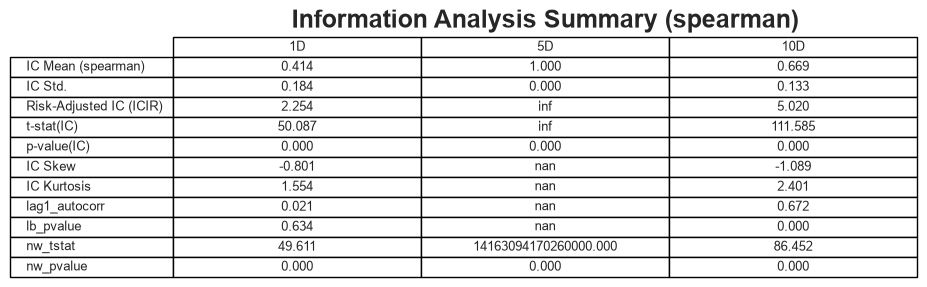

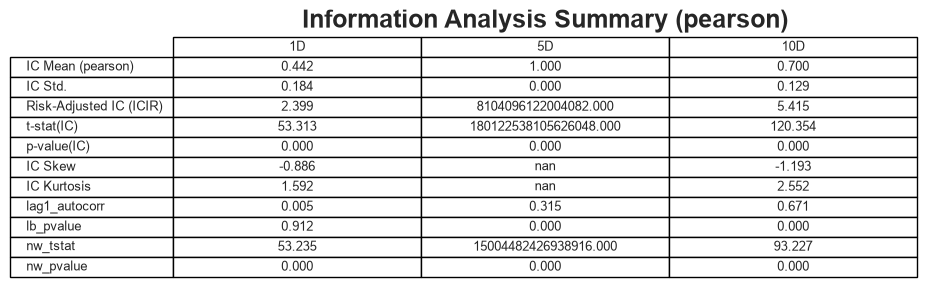

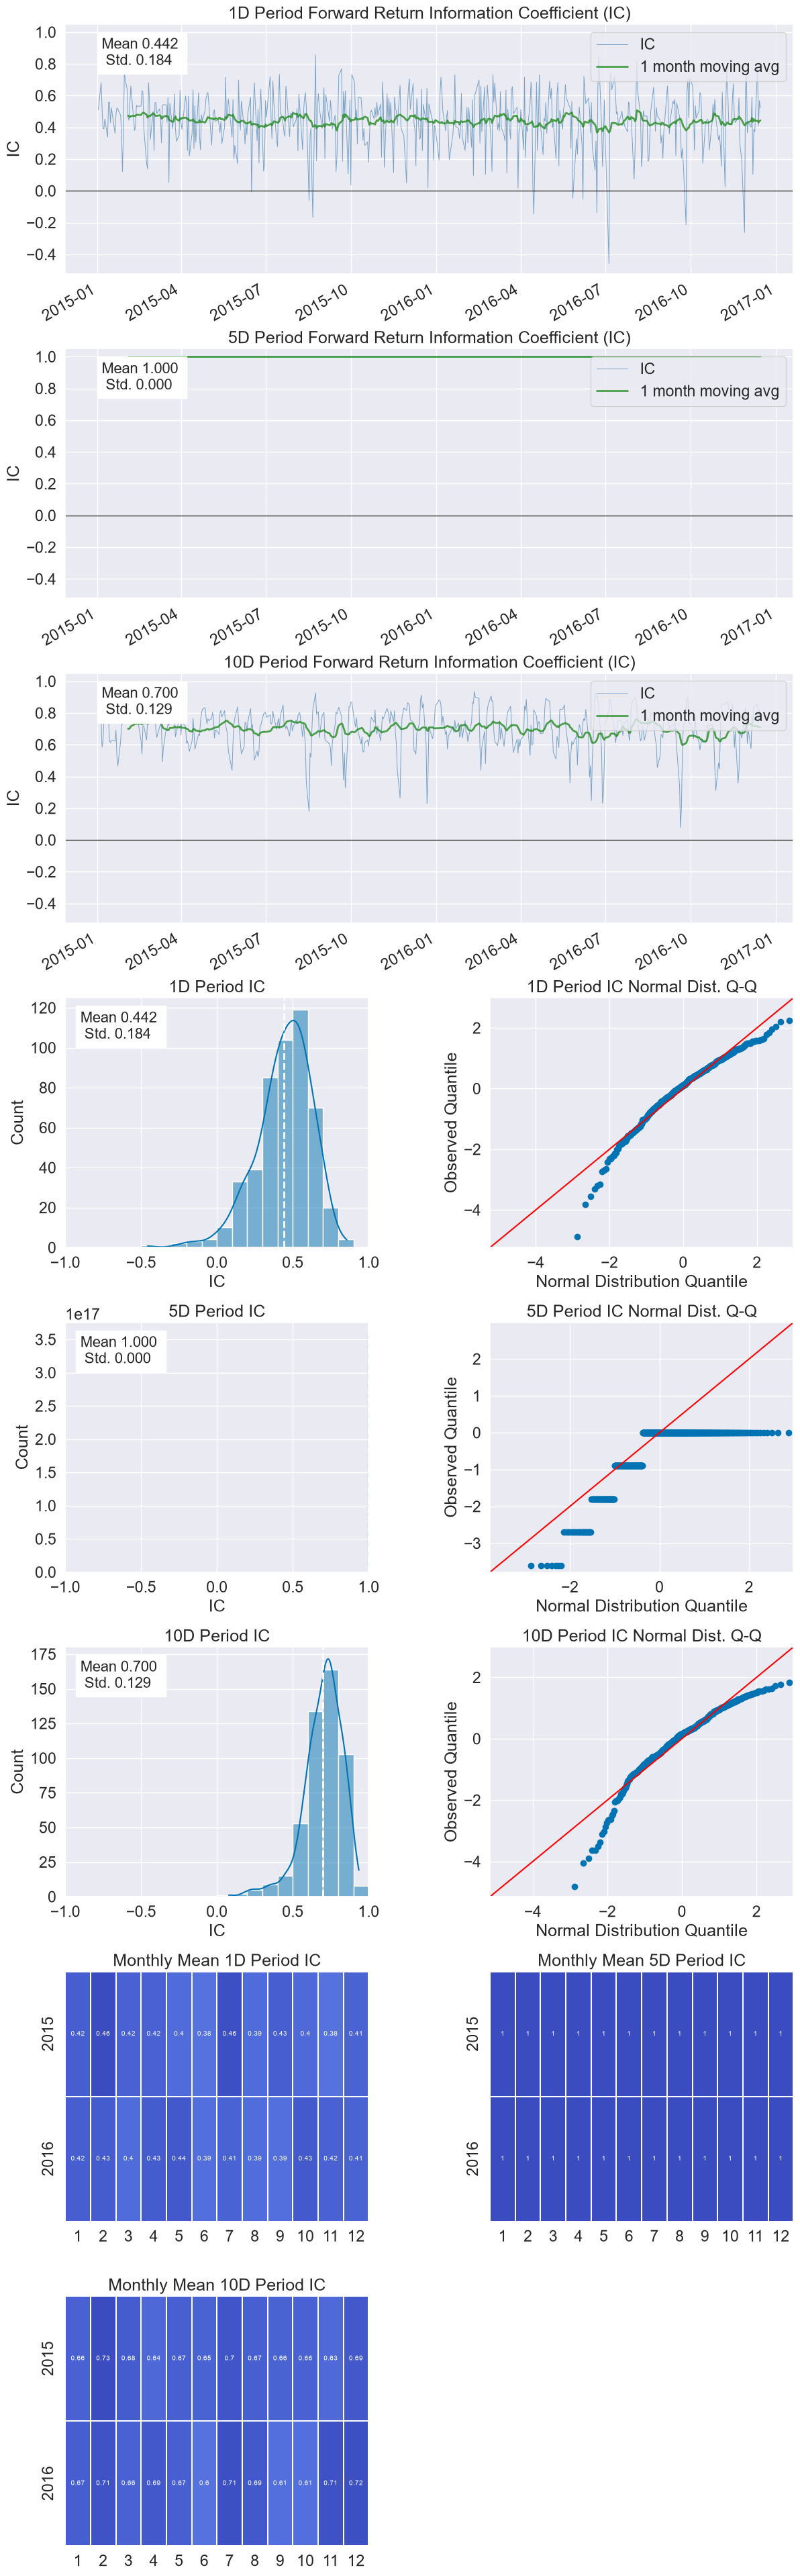

In [36]:
alphalens.tears.create_information_tear_sheet(factor_data);

# Turnover Analysis

Turnover Analysis gives us an idea about the nature of a factor's makeup and how it changes.

## Performance Metrics & Plotting Functions

In [37]:
quantile_factor = factor_data['factor_quantile']
turnover_period = 1

In [38]:
quantiles = range(1, int(quantile_factor.max()) + 1)
quantile_turnover = pd.concat([alphalens.performance.quantile_turnover(quantile_factor, q, 
                                                                       turnover_period)
                               for q in quantiles], axis=1)

In [39]:
quantile_turnover.head()

,1,2,3,4,5
date,,,,,
2015-01-02 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN
2015-01-05 00:00:00+00:00,0.300000,0.517241,0.517241,0.413793,0.166667
2015-01-06 00:00:00+00:00,0.266667,0.586207,0.551724,0.379310,0.200000
2015-01-07 00:00:00+00:00,0.366667,0.724138,0.758621,0.586207,0.200000
2015-01-08 00:00:00+00:00,0.266667,0.655172,0.586207,0.551724,0.400000


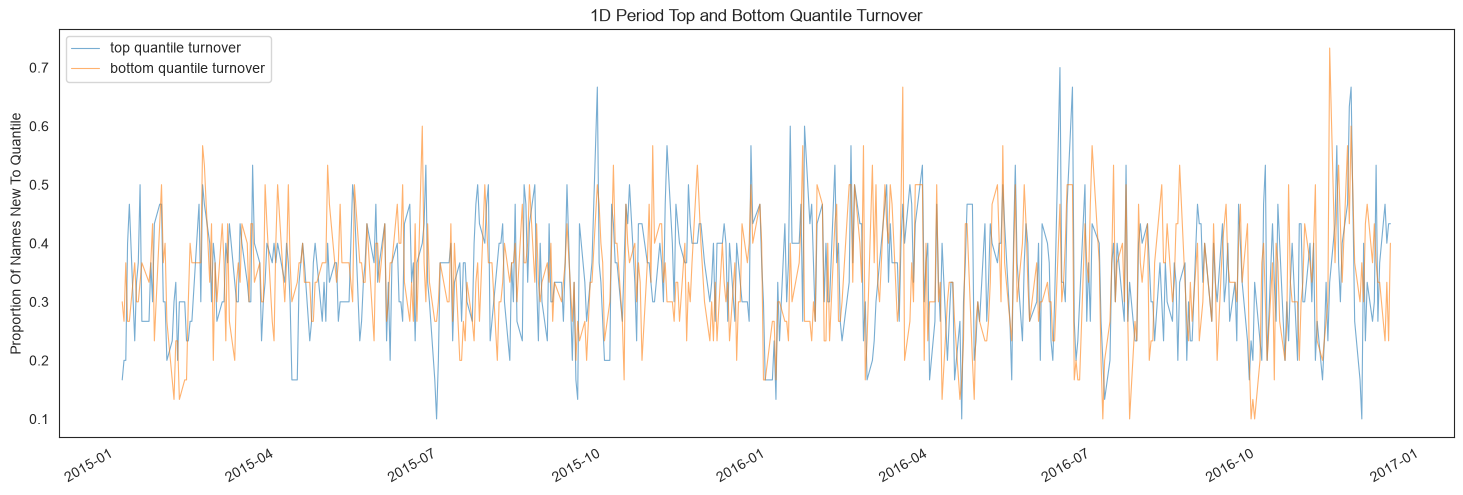

In [40]:
alphalens.plotting.plot_top_bottom_quantile_turnover(quantile_turnover, 
                                                     turnover_period);

Factor turnover is important as it indicates the incorporation of new information and the make up of the extremes of a signal. By looking at the new additions to the sets of top and bottom quantiles we can see how much of this factor is getting remade everyday.

In [41]:
factor_autocorrelation = alphalens.performance.factor_rank_autocorrelation(factor_data, 
                                                                           turnover_period)

In [42]:
factor_autocorrelation.head()

date
2015-01-02 00:00:00+00:00         NaN
2015-01-05 00:00:00+00:00    0.900809
2015-01-06 00:00:00+00:00    0.859878
2015-01-07 00:00:00+00:00    0.814336
2015-01-08 00:00:00+00:00    0.727599
Freq: C, Name: 1, dtype: float64

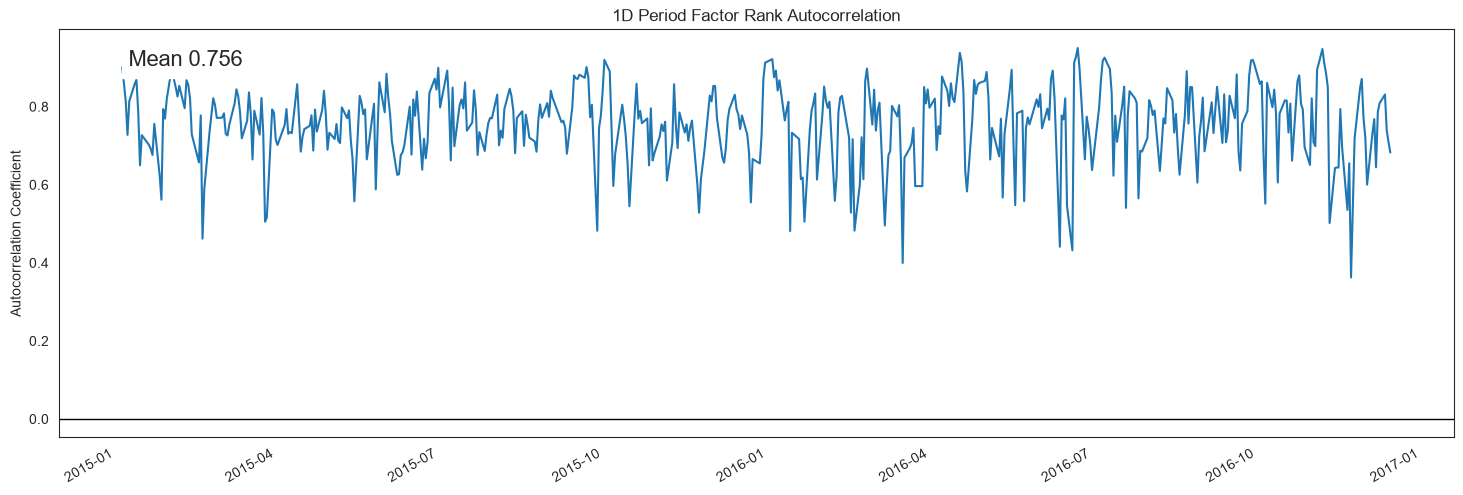

In [43]:
alphalens.plotting.plot_factor_rank_auto_correlation(factor_autocorrelation);

The autocorrelation of the factor indicates to us the persistence of the signal itself.

## Turnover Tear Sheet

We can view all turnover calculations together.

Turnover Analysis


,1D,5D,10D
Quantile 1 Mean Turnover,0.343,0.767,0.782
Quantile 2 Mean Turnover,0.601,0.792,0.796
Quantile 3 Mean Turnover,0.642,0.787,0.787
Quantile 4 Mean Turnover,0.607,0.792,0.799
Quantile 5 Mean Turnover,0.346,0.781,0.790


,1D,5D,10D
Mean Factor Rank Autocorrelation,0.756,0.001,-0.029


<Figure size 640x480 with 0 Axes>

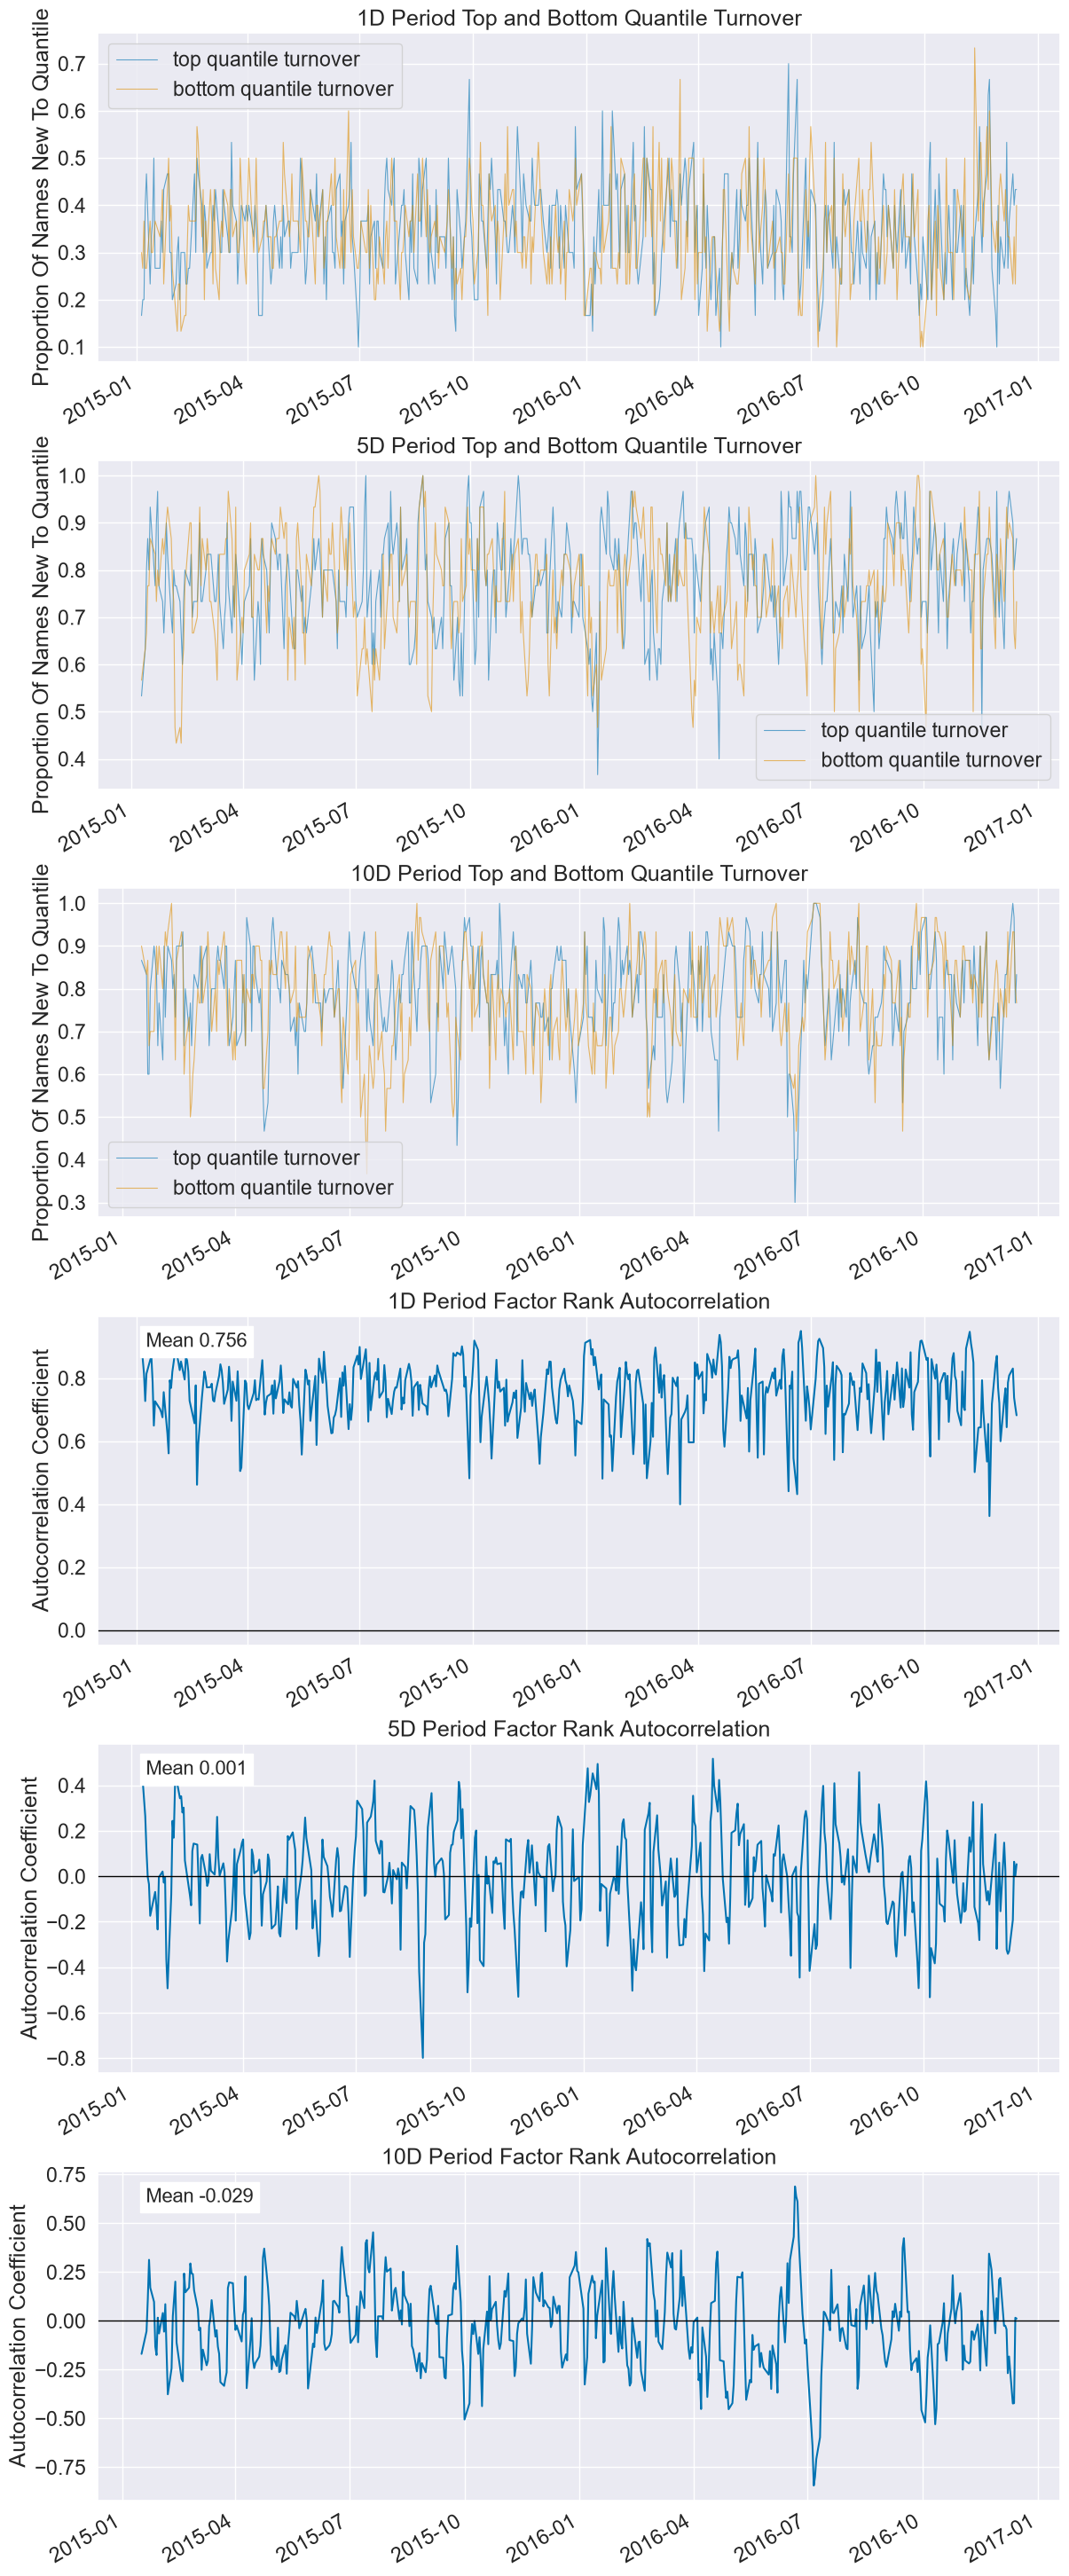

In [44]:
alphalens.tears.create_turnover_tear_sheet(factor_data);

# Event Style Returns Analysis

Looking at the average cumulative return in a window before and after a factor can indicate to us how long the predicative power of a factor lasts. This tear sheet takes a while to run.

**NOTE:** This tear sheet takes in an extra argument `pricing`.

<Figure size 640x480 with 0 Axes>

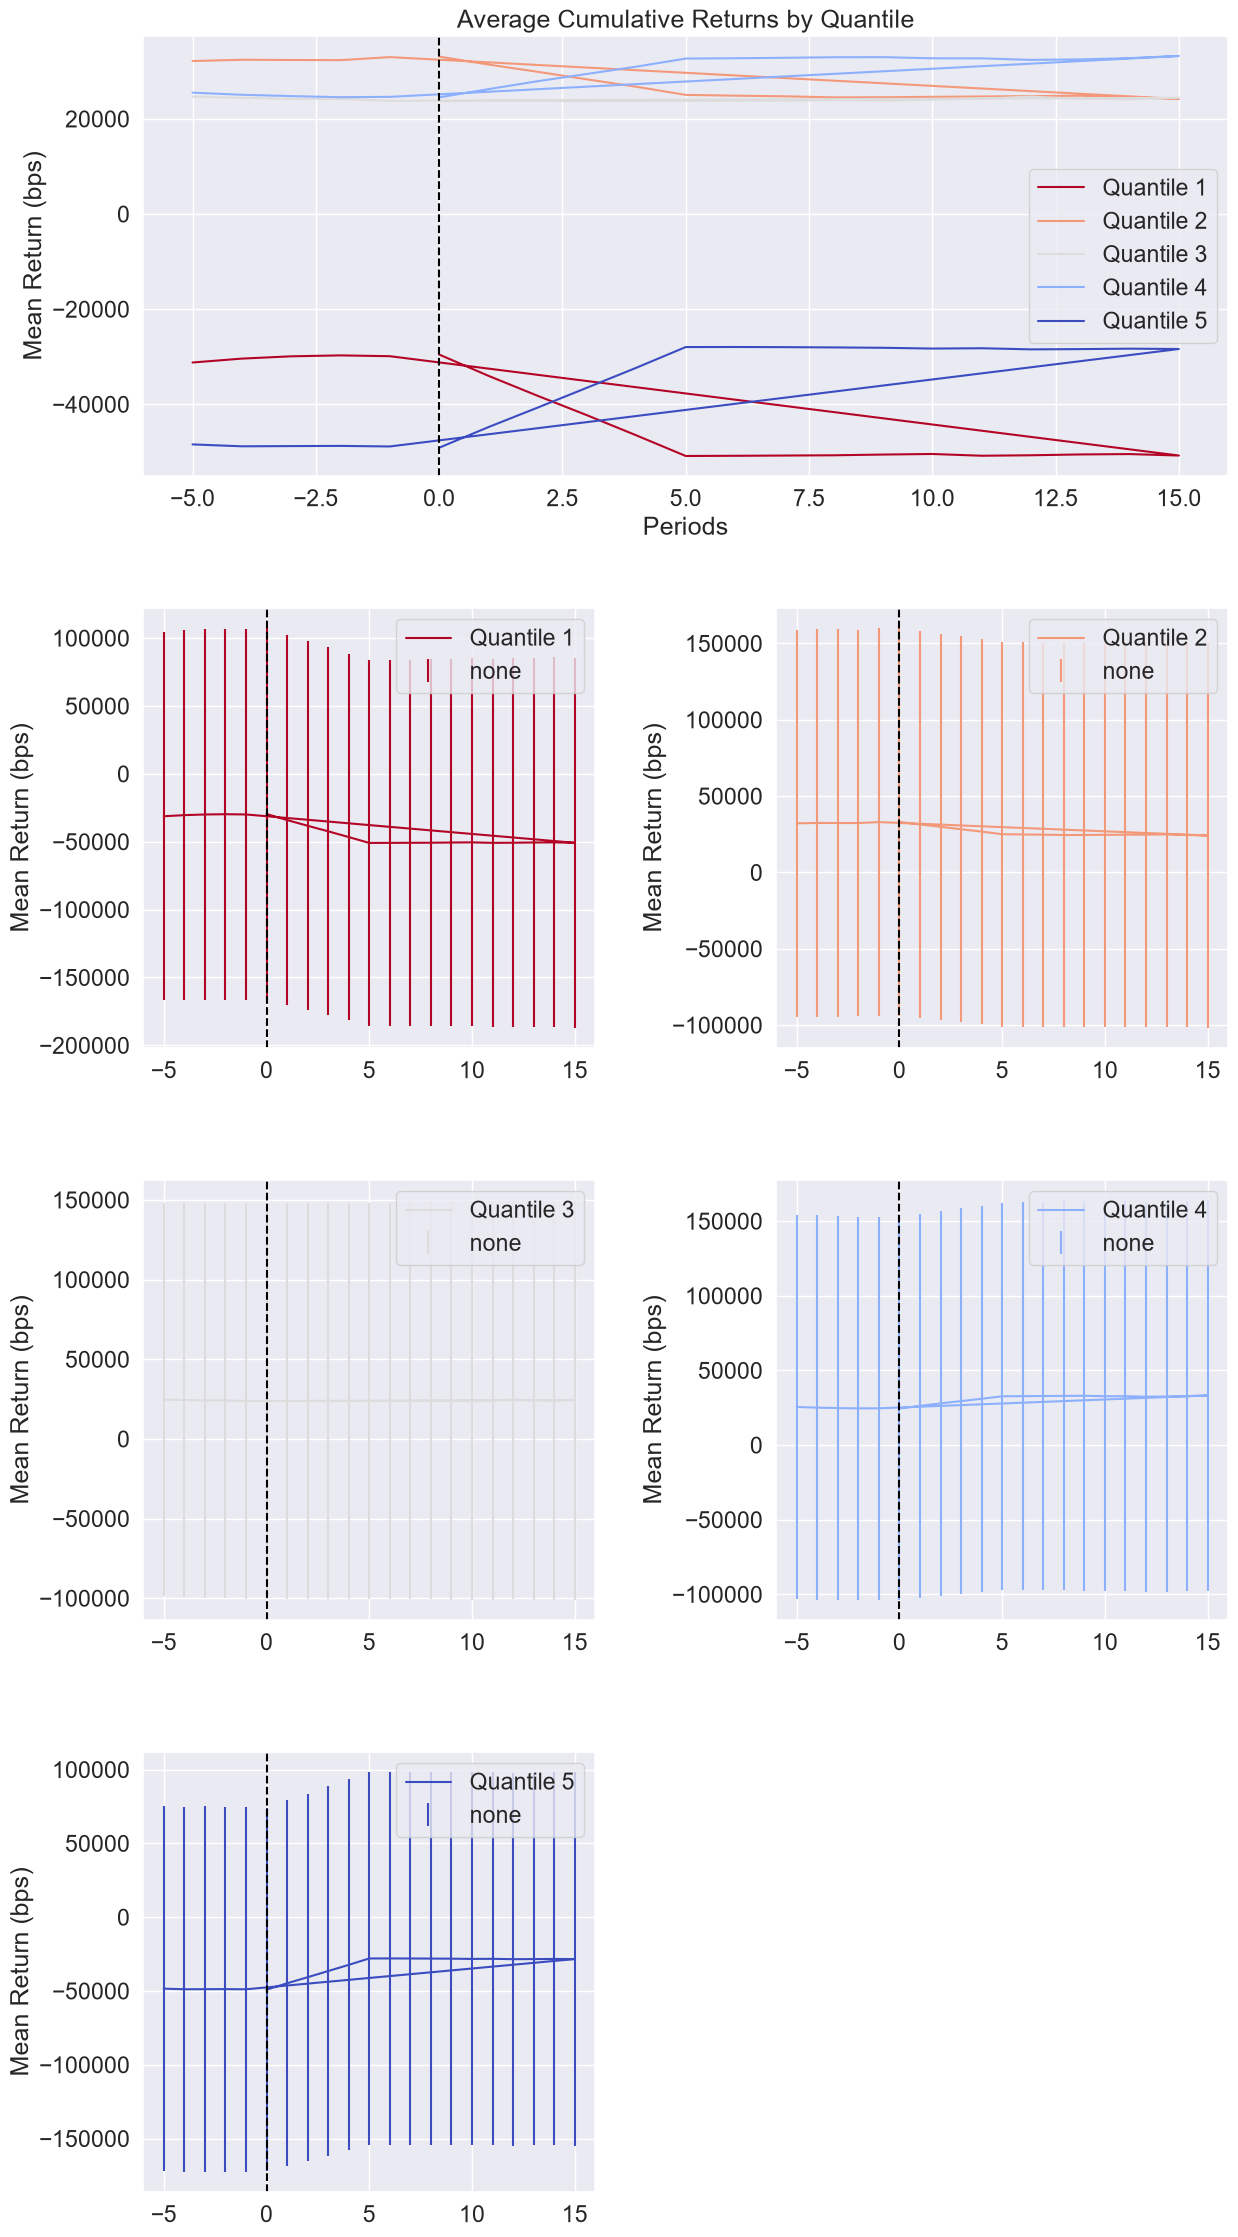

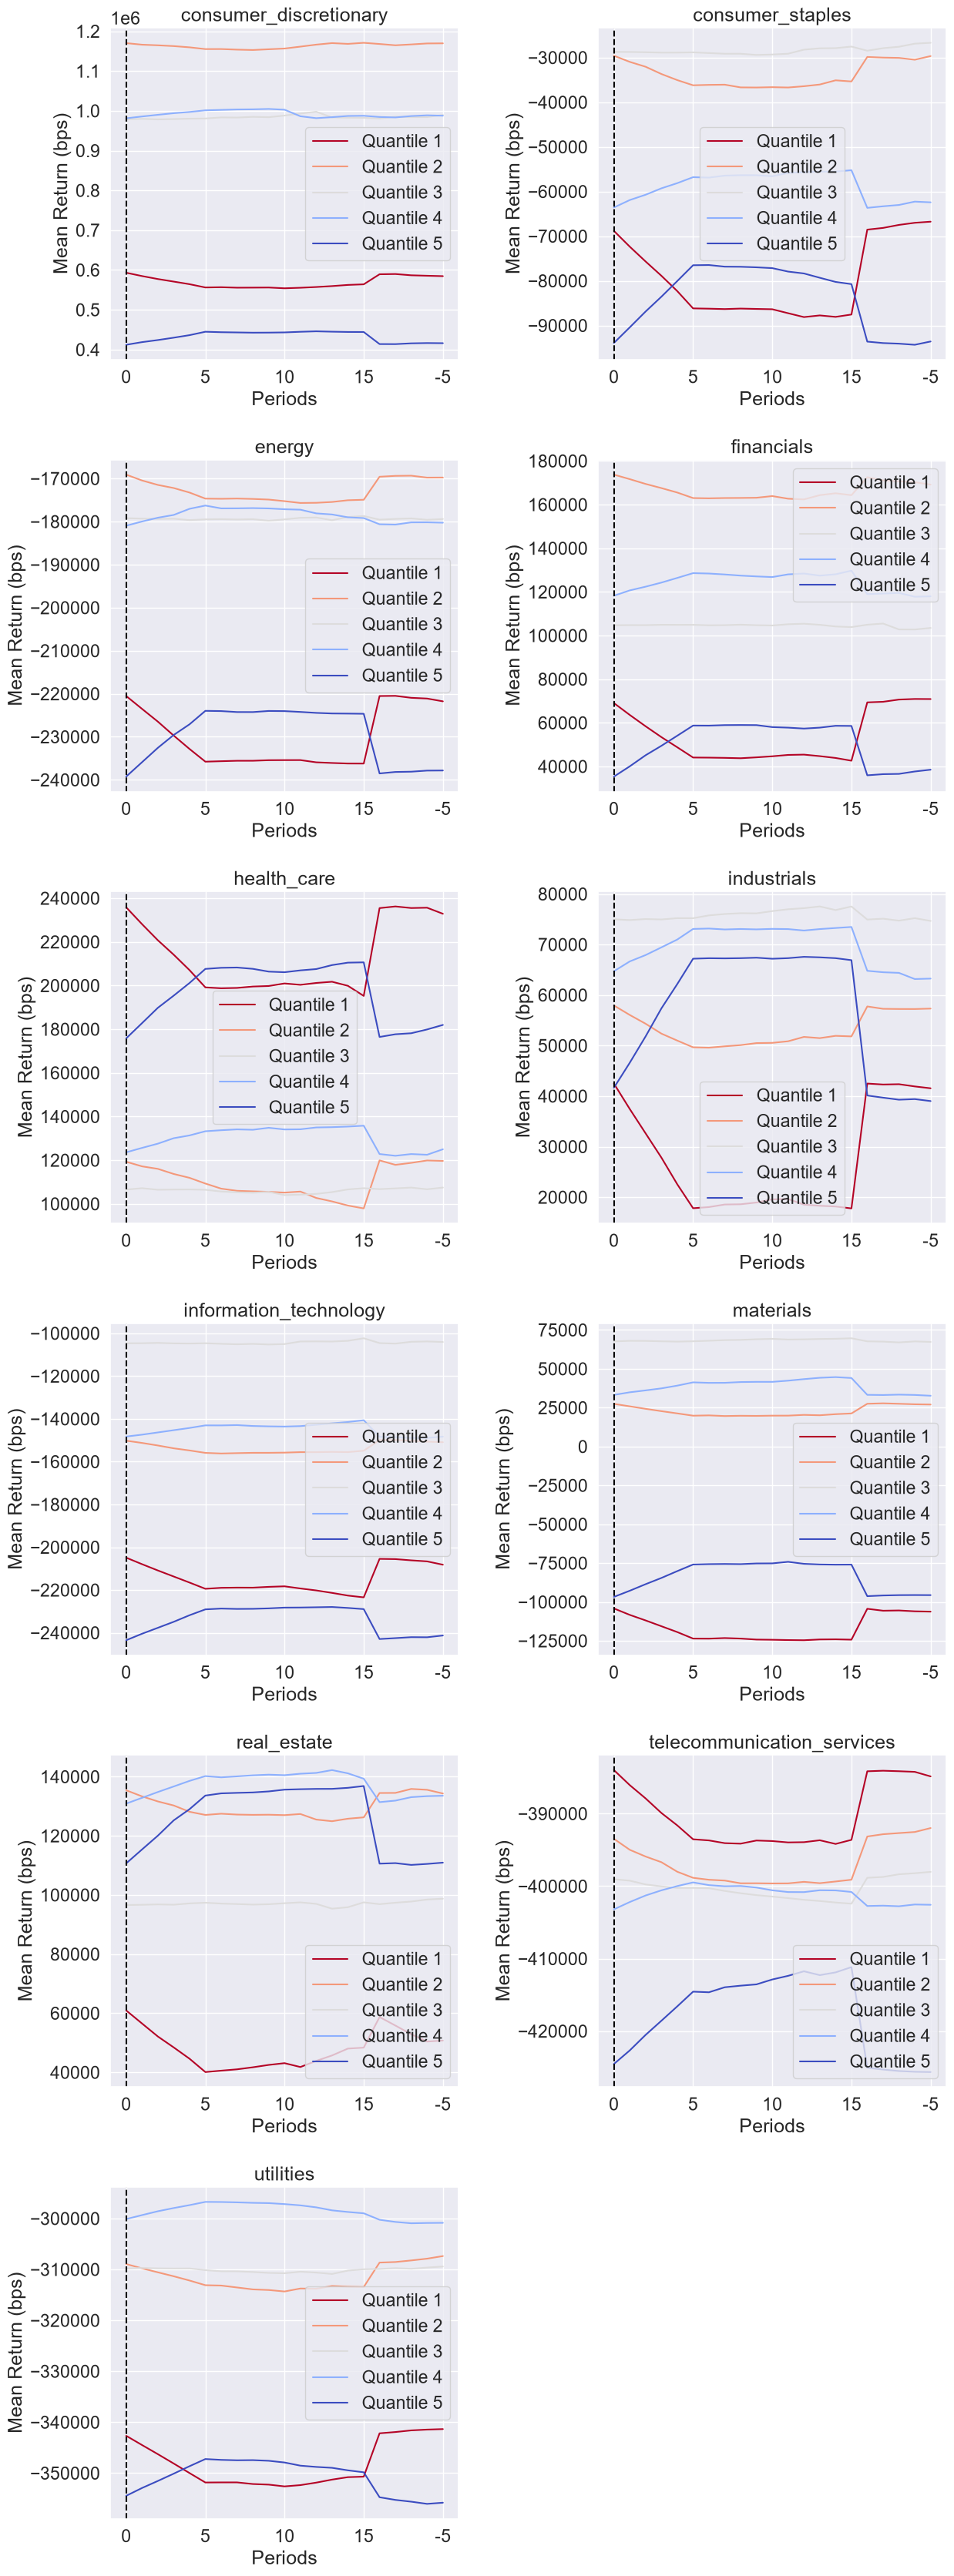

In [45]:
alphalens.tears.create_event_returns_tear_sheet(factor_data, 
                                                pricing, 
                                                by_group=True);

# Groupwise Performance

Many of the plots in Alphalens can be viewed on their own by grouping if grouping information is provided. The returns and information tear sheets can be viewed groupwise by passing in the `by_group=True` argument.

In [46]:
ic_by_sector = alphalens.performance.mean_information_coefficient(factor_data, 
                                                                  by_group=True)

In [47]:
ic_by_sector.head()

,1D,5D,10D
group,,,
consumer_discretionary,0.371698,1.0,0.624446
consumer_staples,0.389111,1.0,0.648631
energy,0.367685,1.0,0.625175
financials,0.407612,1.0,0.646731
health_care,0.387135,1.0,0.615039


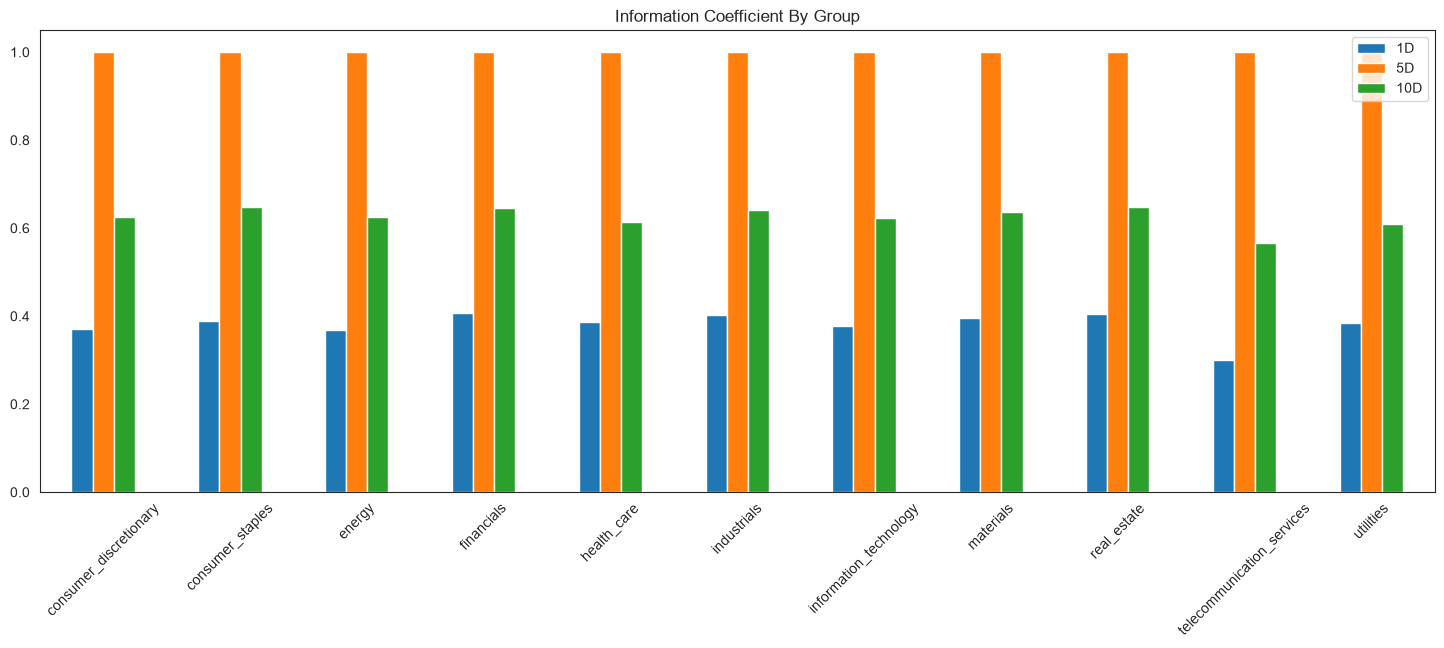

In [48]:
alphalens.plotting.plot_ic_by_group(ic_by_sector);

In [49]:
mean_return_quantile_sector, mean_return_quantile_sector_err = alphalens.performance.mean_return_by_quantile(factor_data, 
                                                                                                             by_group=True)

In [50]:
mean_return_quantile_sector.head()

1D        5D       10D
factor_quantile group                                               
1               consumer_discretionary -0.008217 -0.041532 -0.041916
                consumer_staples       -0.007240 -0.035087 -0.036531
                energy                 -0.008682 -0.043314 -0.041794
                financials             -0.008078 -0.038615 -0.039396
                health_care            -0.007885 -0.040475 -0.037540

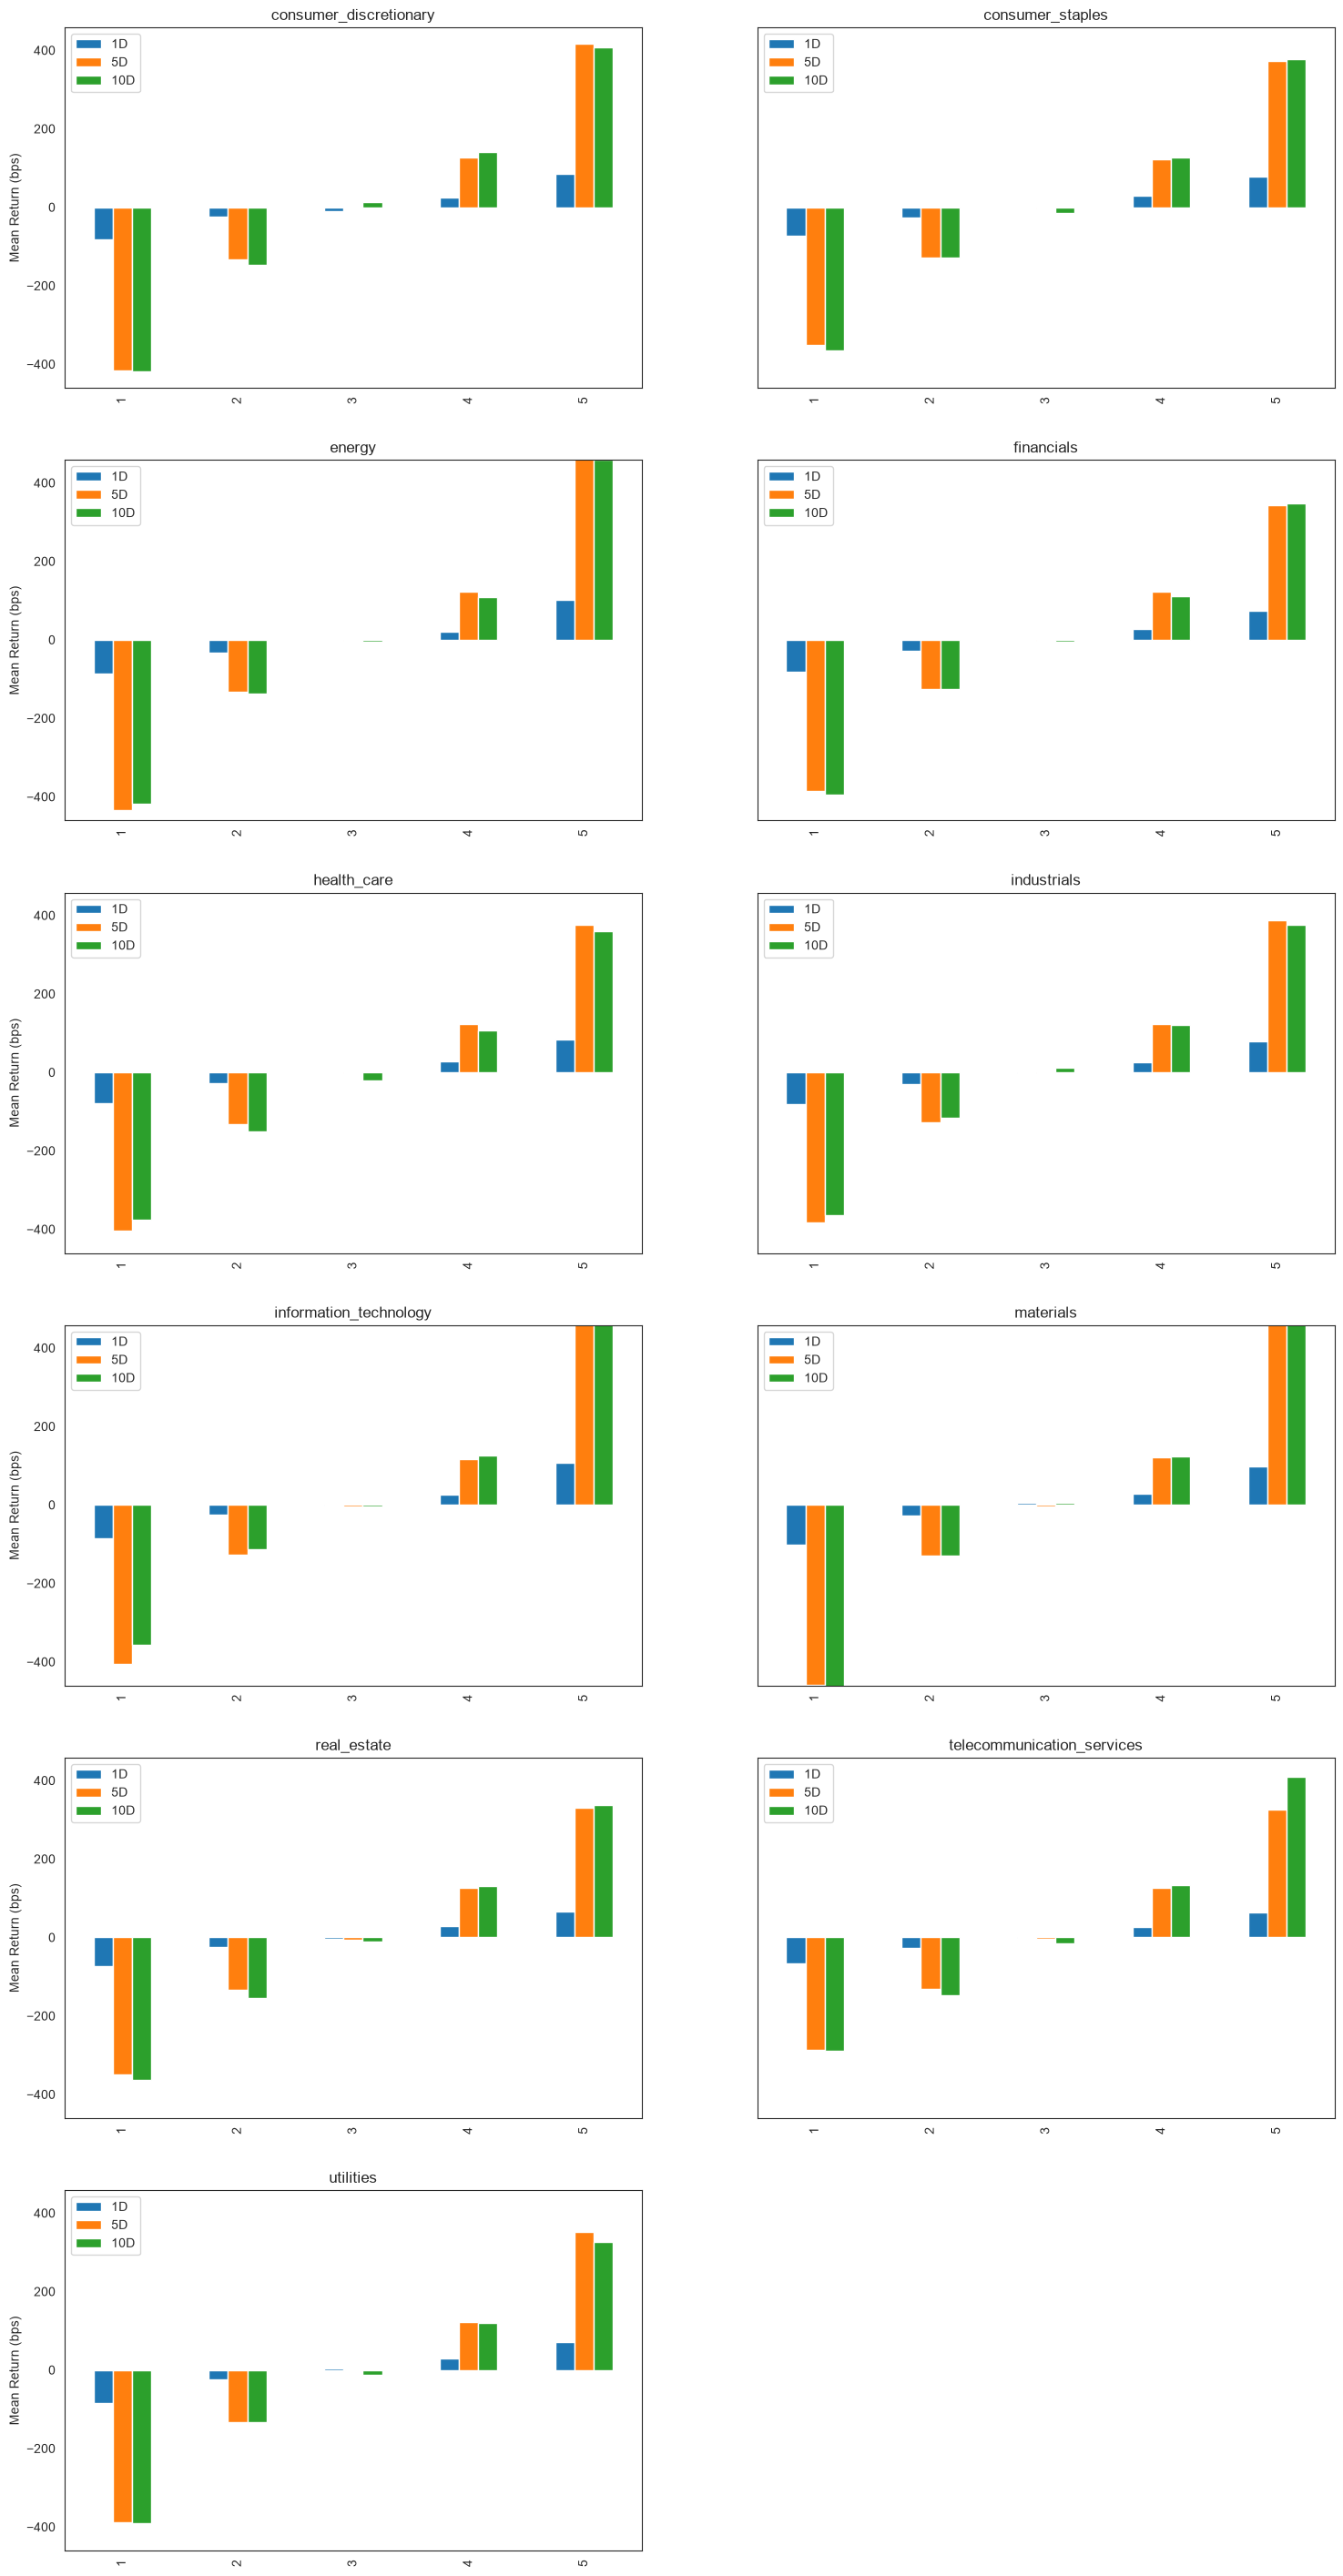

In [51]:
alphalens.plotting.plot_quantile_returns_bar(mean_return_quantile_sector, 
                                             by_group=True);

# Summary Tear Sheet

There are a lot of plots above. If you want a quick snapshot of how the alpha factor performs consider the summary tear sheet.

Quantiles Statistics


,min,max,mean,std,count,count %
factor_quantile,,,,,,
1,-0.362876,0.029829,-0.038085,0.032357,14820,20.408444
2,-0.127435,0.046965,-0.010945,0.019021,14326,19.728163
3,-0.107485,0.069289,0.001941,0.017730,14326,19.728163
4,-0.083241,0.098541,0.014675,0.018697,14326,19.728163
5,-0.061205,0.494950,0.043730,0.036619,14819,20.407067


Returns Analysis


,1D,5D,10D
Ann. alpha,8.550,7.895,1.977
beta,0.095,0.075,0.065
Mean Period Wise Return Top Quantile (bps),84.906,81.579,41.022
Mean Period Wise Return Bottom Quantile (bps),-84.503,-82.045,-41.113
Mean Period Wise Spread (bps),169.409,163.634,82.155


Information Analysis (spearman)


,1D,5D,10D
IC Mean (spearman),0.414,1.000000e+00,0.669
IC Std.,0.184,0.000000e+00,0.133
Risk-Adjusted IC (ICIR),2.254,inf,5.020
t-stat(IC),50.087,inf,111.585
p-value(IC),0.000,0.000000e+00,0.000
IC Skew,-0.801,NaN,-1.089
IC Kurtosis,1.554,NaN,2.401
lag1_autocorr,0.021,NaN,0.672
lb_pvalue,0.634,NaN,0.000
nw_tstat,49.611,1.416309e+16,86.452


Turnover Analysis


,1D,5D,10D
Quantile 1 Mean Turnover,0.343,0.767,0.782
Quantile 2 Mean Turnover,0.601,0.792,0.796
Quantile 3 Mean Turnover,0.642,0.787,0.787
Quantile 4 Mean Turnover,0.607,0.792,0.799
Quantile 5 Mean Turnover,0.346,0.781,0.790


,1D,5D,10D
Mean Factor Rank Autocorrelation,0.756,0.001,-0.029


<Figure size 640x480 with 0 Axes>

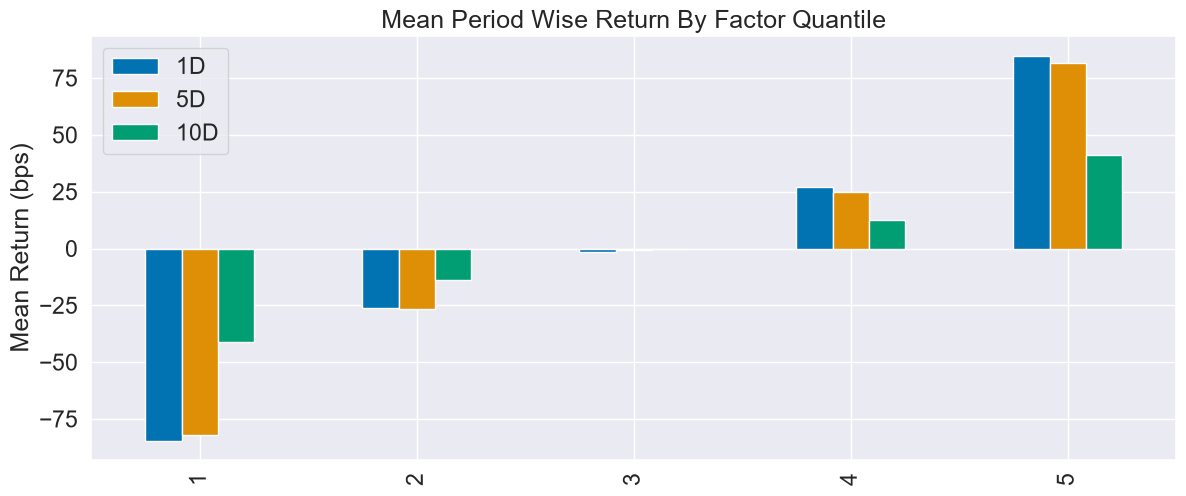

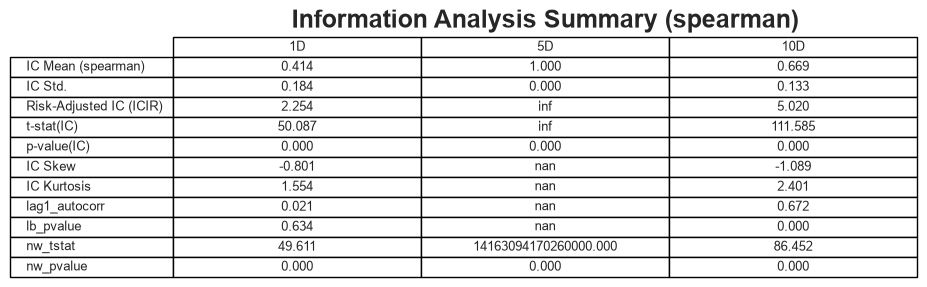

In [52]:
alphalens.tears.create_summary_tear_sheet(factor_data)

# The Whole Thing

If you want to see all of the results create a full tear sheet. By passing in the factor data you can analyze all of the above statistics and plots at once.

Quantiles Statistics


,min,max,mean,std,count,count %
factor_quantile,,,,,,
1,-0.362876,0.029829,-0.038085,0.032357,14820,20.408444
2,-0.127435,0.046965,-0.010945,0.019021,14326,19.728163
3,-0.107485,0.069289,0.001941,0.017730,14326,19.728163
4,-0.083241,0.098541,0.014675,0.018697,14326,19.728163
5,-0.061205,0.494950,0.043730,0.036619,14819,20.407067


Returns Analysis


,1D,5D,10D
Ann. alpha,8.550,7.895,1.977
beta,0.095,0.075,0.065
Mean Period Wise Return Top Quantile (bps),84.906,81.579,41.022
Mean Period Wise Return Bottom Quantile (bps),-84.503,-82.045,-41.113
Mean Period Wise Spread (bps),169.409,163.634,82.155


<Figure size 640x480 with 0 Axes>

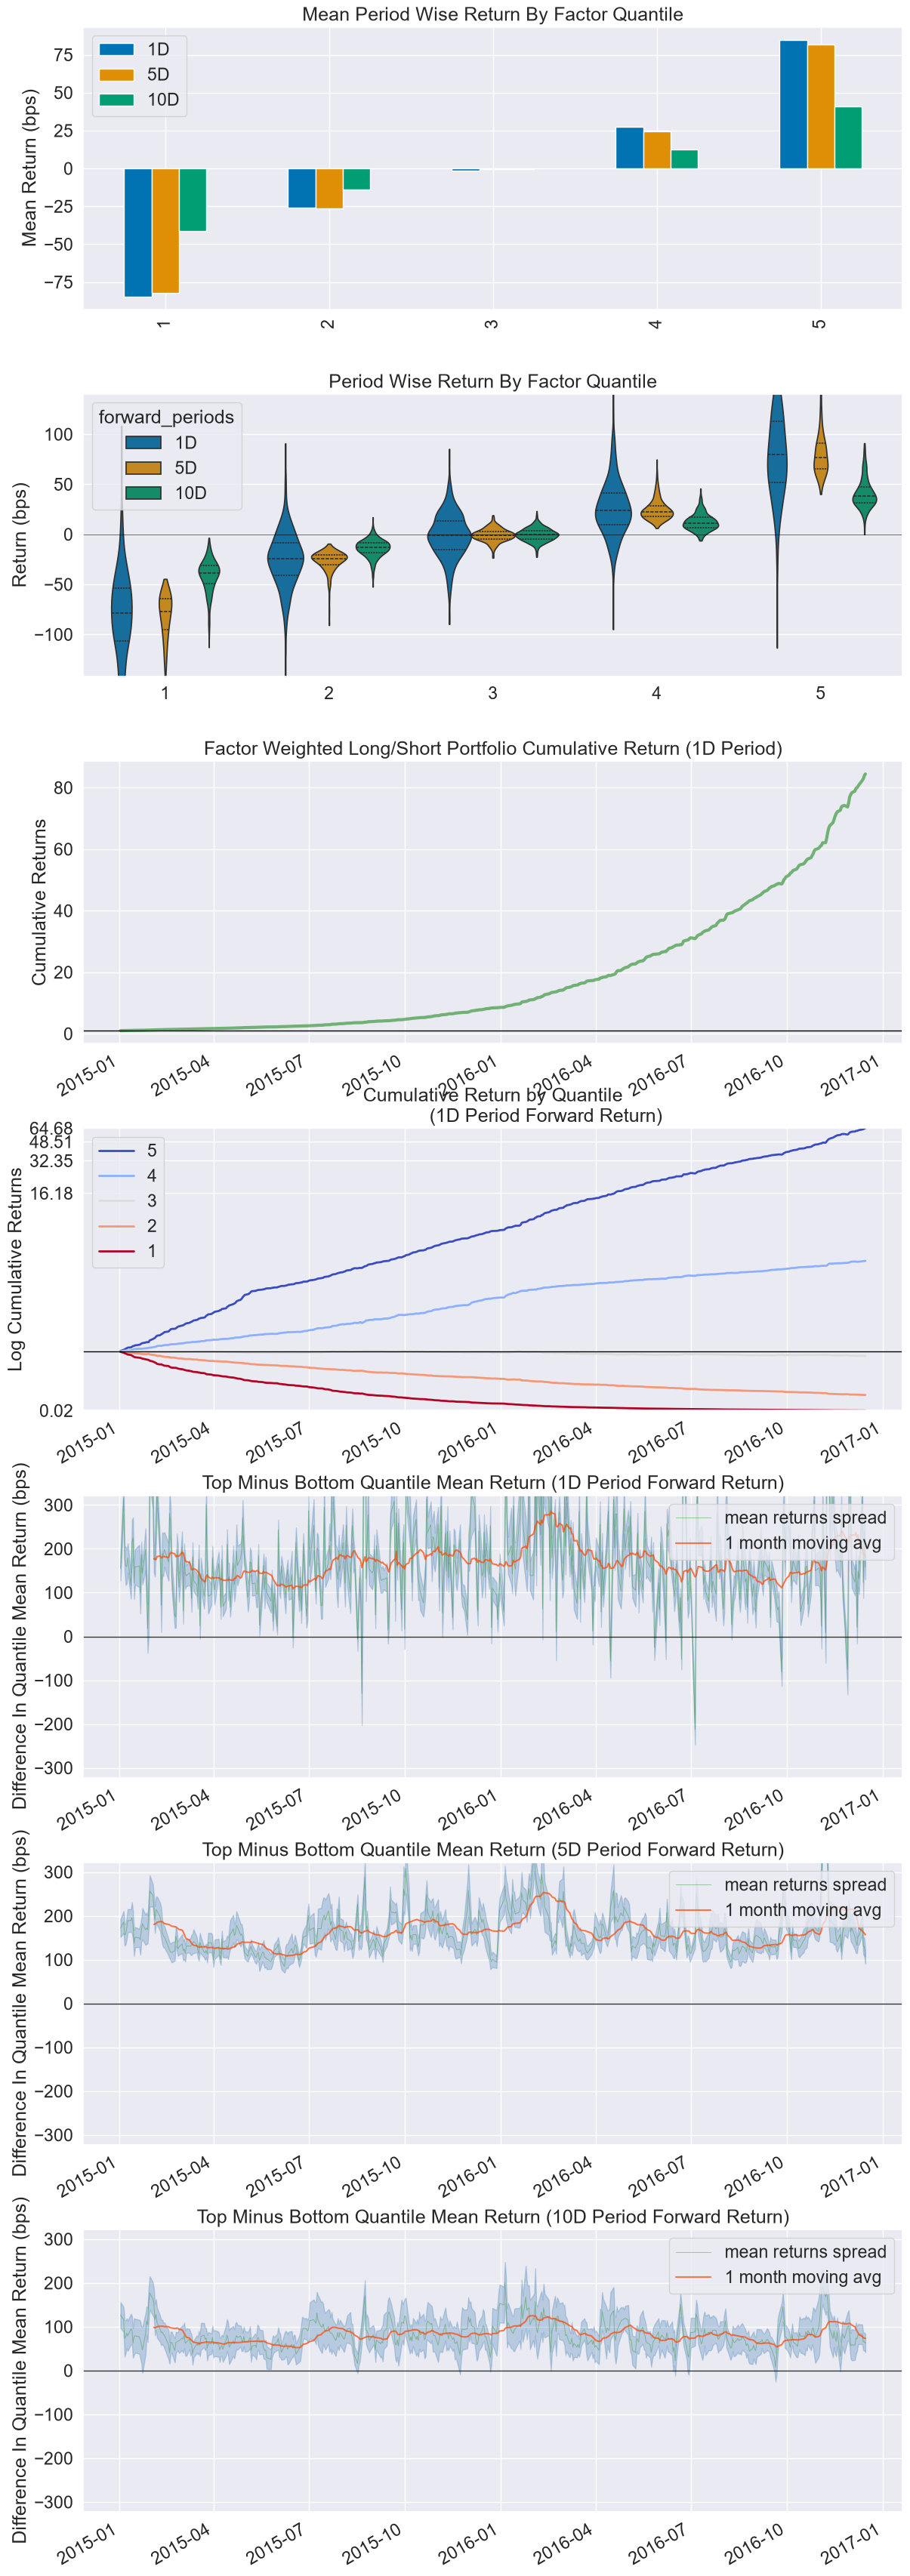

Information Analysis (spearman)


,1D,5D,10D
IC Mean (spearman),0.414,1.000000e+00,0.669
IC Std.,0.184,0.000000e+00,0.133
Risk-Adjusted IC (ICIR),2.254,inf,5.020
t-stat(IC),50.087,inf,111.585
p-value(IC),0.000,0.000000e+00,0.000
IC Skew,-0.801,NaN,-1.089
IC Kurtosis,1.554,NaN,2.401
lag1_autocorr,0.021,NaN,0.672
lb_pvalue,0.634,NaN,0.000
nw_tstat,49.611,1.416309e+16,86.452


Information Analysis (pearson)


,1D,5D,10D
IC Mean (pearson),0.442,1.000000e+00,0.700
IC Std.,0.184,0.000000e+00,0.129
Risk-Adjusted IC (ICIR),2.399,8.104096e+15,5.415
t-stat(IC),53.313,1.801225e+17,120.354
p-value(IC),0.000,0.000000e+00,0.000
IC Skew,-0.886,NaN,-1.193
IC Kurtosis,1.592,NaN,2.552
lag1_autocorr,0.005,3.150000e-01,0.671
lb_pvalue,0.912,0.000000e+00,0.000
nw_tstat,53.235,1.500448e+16,93.227


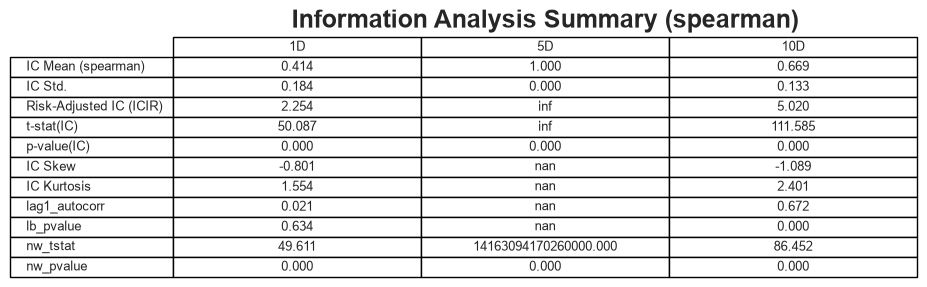

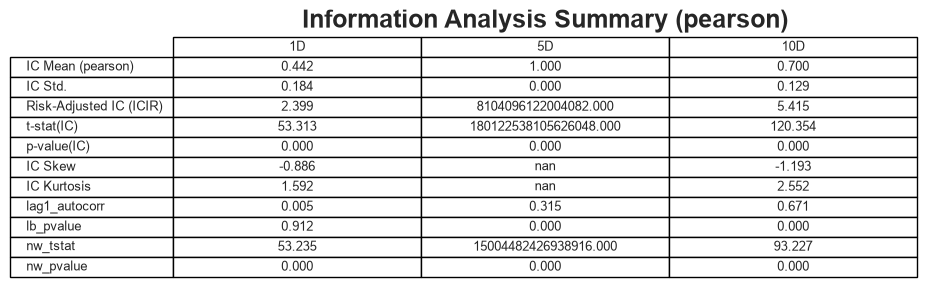

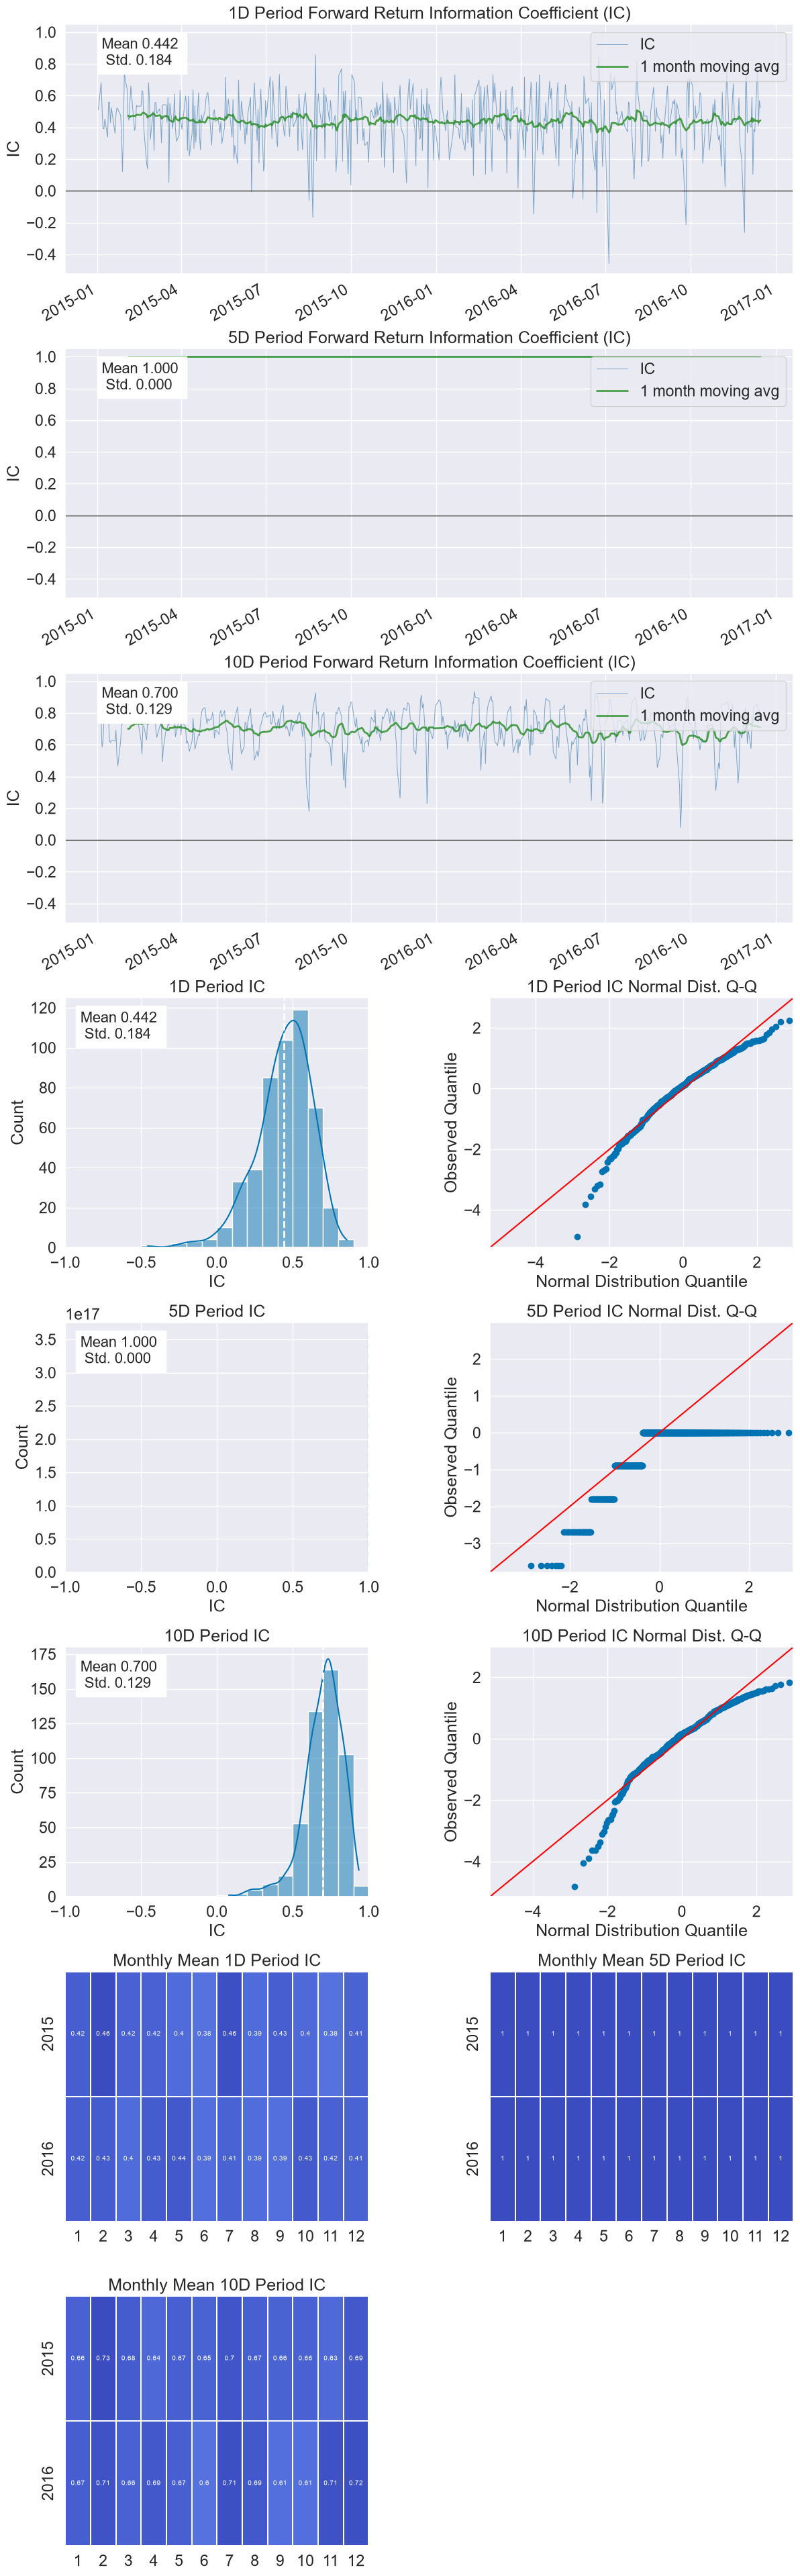

Turnover Analysis


,1D,5D,10D
Quantile 1 Mean Turnover,0.343,0.767,0.782
Quantile 2 Mean Turnover,0.601,0.792,0.796
Quantile 3 Mean Turnover,0.642,0.787,0.787
Quantile 4 Mean Turnover,0.607,0.792,0.799
Quantile 5 Mean Turnover,0.346,0.781,0.790


,1D,5D,10D
Mean Factor Rank Autocorrelation,0.756,0.001,-0.029


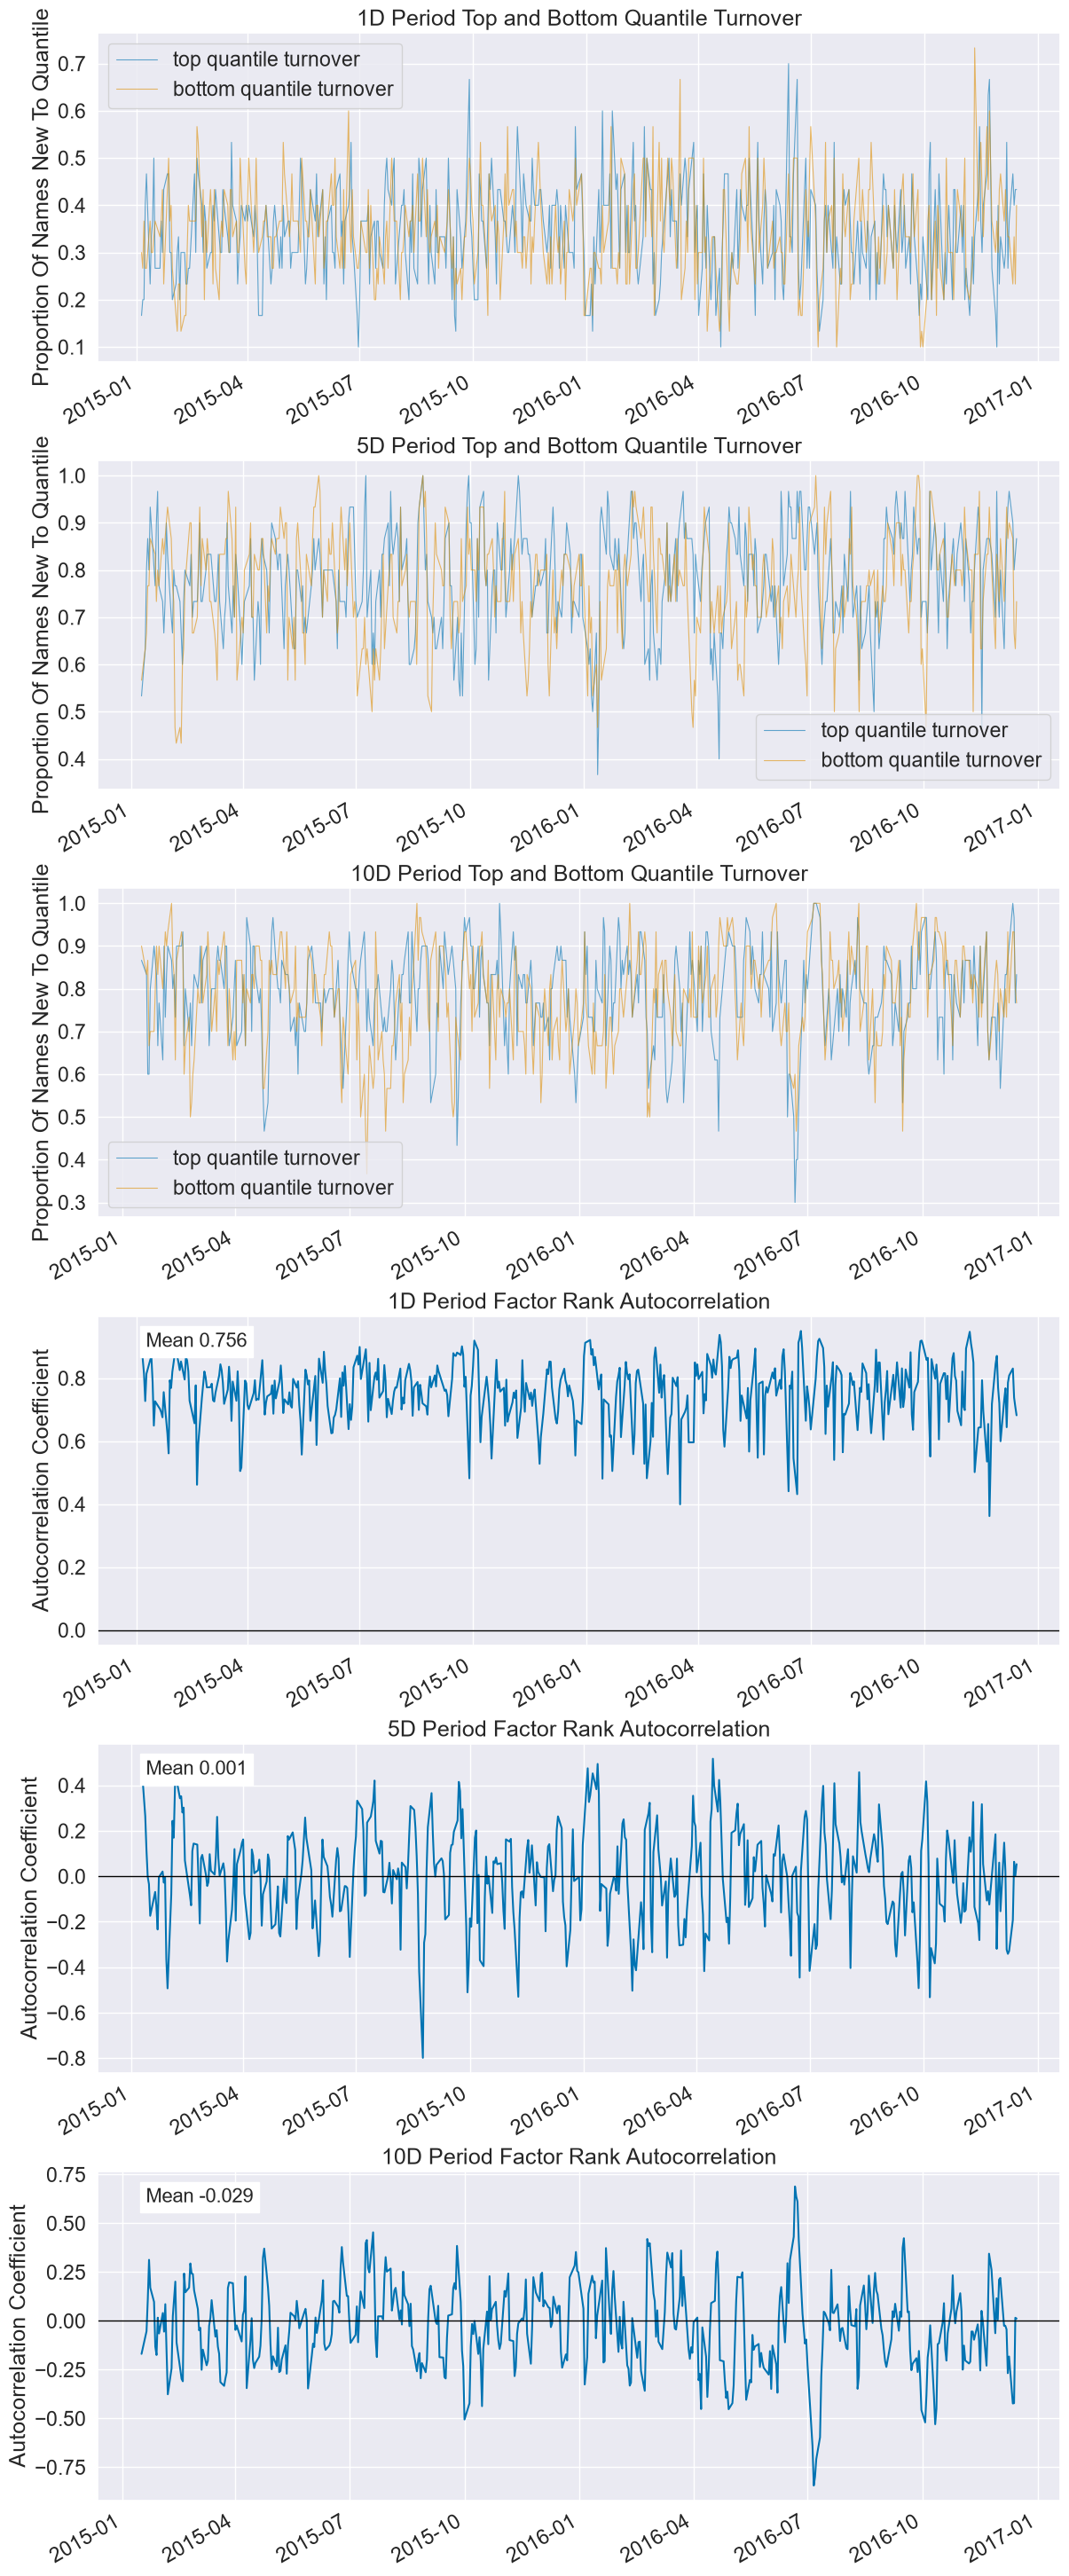

In [53]:
alphalens.tears.create_full_tear_sheet(factor_data)